# **Fase 2 · 7.1 Replicación del método sobre el conjunto original**

Este cuaderno reproduce el método de Benítez-Andrades et al. (2022) sobre el conjunto de datos que los autores publican (Zenodo, 2,000 tuits). Se parte de la comparación con dos referencias: la **Tabla 5 del artículo** y las **salidas de los cuadernos publicados por los autores** (`jupyter/*.ipynb`). Los resultados de la entrega anterior (mBERT 34.23 %, LSTM 32.42 %, CNN 50.55 %) se tratan como posibles fallas de implementación y se diagnostican antes de interpretarlos.

Decisiones de diseño:

- Se replica el preprocesamiento, la partición y los hiperparámetros **tal como están en el código publicado**, y se documentan las discrepancias entre el artículo y su código.
- Cada configuración se entrena con **varias semillas** (redes: 5; BETO uncased: 3; BETO cased y mBERT: 2) y se reporta media, desviación y rango, porque una sola corrida no permite saber si la diferencia frente al artículo es real o es ruido de entrenamiento.
- El conjunto de prueba (600 tuits) **no se usa para elegir nada**: los epochs son fijos (como en el código de los autores) o se detienen con una validación tomada del entrenamiento.
- Cada corrida se acompaña de diagnósticos: distribución de predicciones, matriz de confusión y curvas de entrenamiento.

## 1. Configuración, semillas y librerías

Se usa TensorFlow con Keras 2 (`TF_USE_LEGACY_KERAS=1`) para que los modelos de Hugging Face y los de Keras compartan el mismo motor. La variable debe fijarse **antes** de importar TensorFlow: mezclar Keras 3 con los modelos de Hugging Face es una fuente conocida de entrenamientos que no actualizan los pesos.

In [1]:
import os, sys, json, time, random, zipfile, urllib.request, re
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import transformers
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_recall_fscore_support, accuracy_score, confusion_matrix

import tf_keras
print("TensorFlow:", tf.__version__, "| tf-keras (Keras 2):", tf_keras.__version__, "| Transformers:", transformers.__version__)
print("Dispositivos:", [d.name for d in tf.config.list_physical_devices()])

SALIDAS = Path("salidas_71")
SALIDAS.mkdir(exist_ok=True)
SEMILLAS_REDES = [0, 1, 2, 3, 4]
SEMILLAS_BERT = [0, 1, 2]
RAPIDO = os.environ.get("REPLICA_RAPIDO") == "1"   # solo para depurar el código
if RAPIDO:
    SEMILLAS_REDES, SEMILLAS_BERT = [0], [0]

def fijar_semilla(s):
    os.environ["PYTHONHASHSEED"] = str(s)
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

TensorFlow: 2.18.1 | tf-keras (Keras 2): 2.18.0 | Transformers: 4.57.6
Dispositivos: ['/physical_device:CPU:0', '/physical_device:GPU:0']


## 2. Valores de referencia

**Tabla 5 del artículo** (macro-promedio sobre el conjunto de prueba de 600 tuits; las matrices de confusión de la Figura 6 suman 600) y **salidas de los cuadernos de los autores** en el repositorio. Los cuadernos reportan *accuracy* (la función que llaman `f1` usa `average="micro"`, que equivale a la accuracy) y el reporte de clasificación de las redes.

| Modelo | Tabla 5 (F1 macro, %) | Cuaderno de los autores |
|---|---|---|
| BETO | 85.14 | cased, 4 épocas: accuracy 80.48 % (n = 589) |
| mBERT | 82.00 | cased, 4 épocas: accuracy 79.33 % (n = 600) |
| CNN | 80.15 | F1 macro 0.80 (n = 589) |
| LSTM | 80.27 | F1 macro 0.76 (n = 589) |
| CNN + LSTM | 79.09 | CNN + BiLSTM: F1 macro 0.76 (n = 589) |

Los propios cuadernos de los autores no alcanzan los valores de la Tabla 5 en BETO, mBERT ni LSTM. Por eso la brecha esperable de una replicación fiel no es cero.

In [2]:
TABLA5 = pd.DataFrame({
    "modelo": ["BETO", "mBERT", "CNN", "LSTM", "CNN+LSTM"],
    "P_macro": [85.22, 82.00, 80.17, 80.48, 79.34],
    "R_macro": [85.12, 82.02, 80.14, 80.24, 79.07],
    "F1_macro": [85.14, 82.00, 80.15, 80.27, 79.09],
}).set_index("modelo")

# Salidas de los cuadernos de los autores (jupyter/*.ipynb)
CUADERNOS = pd.DataFrame({
    "modelo": ["BETO", "mBERT", "CNN", "LSTM", "CNN+LSTM"],
    "metrica": ["accuracy", "accuracy", "F1 macro", "F1 macro", "F1 macro"],
    "valor": [80.48, 79.33, 80.0, 76.0, 76.0],
    "n_prueba": [589, 600, 589, 589, 589],
}).set_index("modelo")

# Matriz de confusión de BETO en la Figura 6 del artículo: [[TN, FP], [FN, TP]]
FIG6_BETO = np.array([[268, 39], [50, 243]])
print("Tabla 5:\n", TABLA5, "\n\nCuadernos:\n", CUADERNOS)
print("\nExactitud implícita en la Figura 6 (BETO):", round((268 + 243) / FIG6_BETO.sum() * 100, 2), "% con n =", FIG6_BETO.sum())

Tabla 5:
           P_macro  R_macro  F1_macro
modelo                              
BETO        85.22    85.12     85.14
mBERT       82.00    82.02     82.00
CNN         80.17    80.14     80.15
LSTM        80.48    80.24     80.27
CNN+LSTM    79.34    79.07     79.09 

Cuadernos:
            metrica  valor  n_prueba
modelo                             
BETO      accuracy  80.48       589
mBERT     accuracy  79.33       600
CNN       F1 macro  80.00       589
LSTM      F1 macro  76.00       589
CNN+LSTM  F1 macro  76.00       589

Exactitud implícita en la Figura 6 (BETO): 85.17 % con n = 600


## 3. Datos y preprocesamiento del artículo

Se obtiene el repositorio de los autores (Zenodo, versión V2) y se reconstruye el preprocesamiento **sin modificarlo**: `clean_tweet` (minúsculas, URL y menciones, acentos, risas, puntuación, *stopwords* del archivo `spanish_stopwords.txt`) y la partición `train_test_split(test_size=0.3, random_state=42)` **sin estratificar**. Las diferencias del archivo de datos con el código publicado (separador `;`, columna `Column1` en lugar de `Unnamed: 0`, y ausencia de `username`) se adaptan sin alterar textos ni etiquetas.

Se verifica que la reconstrucción coincide con los números impresos en los cuadernos de los autores: 1,400 / 600 tuits tras la partición, 1,369 / 589 tras eliminar duplicados y la misma secuencia de índices del primer tuit de entrenamiento.

In [3]:
def obtener_repositorio():
    candidatos = [Path(os.environ.get("REPO_ARTICULO", "")),
                  Path("repositorio_articulo"),
                  *sorted(Path.home().glob("Downloads/jabenitez88-Detecting-racism*"))]
    for c in candidatos:
        if c.is_dir() and (c / "data" / "input_tweets.csv").exists():
            return c
    # Descarga desde Zenodo (registro 5886624)
    meta = json.load(urllib.request.urlopen("https://zenodo.org/api/records/5886624"))
    url = meta["files"][0]["links"]["self"]
    zip_path = Path("articulo_zenodo.zip")
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("repositorio_articulo_zip")
    return next(Path("repositorio_articulo_zip").glob("*"))

REPO = obtener_repositorio()
print("Repositorio de los autores:", REPO.name)

PUNCT = "¡!#$%&'()*+,-./:;<=>¿?@[\\]^_`{|}~"
STOPWORDS = [l.rstrip("\n") for l in open(REPO / "data" / "spanish_stopwords.txt", encoding="utf-8")]

def clean_accents(t):
    t = re.sub(r"[àáâãäå]", "a", t); t = re.sub(r"ç", "c", t); t = re.sub(r"[èéêë]", "e", t)
    t = re.sub(r"[ìíîï]", "i", t); t = re.sub(r"[òóôõö]", "o", t); t = re.sub(r"[ùúûü]", "u", t)
    return re.sub(r"[ýÿ]", "y", t)

def clean_tweet(tweet):
    tweet = tweet.lower().strip()
    tweet = re.sub(r"https?:\/\/\S+", "", tweet); tweet = re.sub(r"http?:\/\/\S+", "", tweet)
    tweet = re.sub(r"www?:\/\/\S+", "", tweet)
    tweet = re.sub(r"\s([@#][\w_-]+)", "", tweet); tweet = re.sub(r"\n", " ", tweet)
    tweet = clean_accents(tweet)
    tweet = re.sub(r"\b(a*ha+h[ha]*|o?l+o+l+[ol]*|x+d+[x*d*]*|a*ja+[j+a+]+)\b", "<risas>", tweet)
    for s in PUNCT:
        tweet = tweet.replace(s, "")
    return " ".join(t for t in tweet.strip().split() if t not in PUNCT and t not in STOPWORDS)

df = pd.read_csv(REPO / "data" / "input_tweets.csv", sep=";")
df["target"] = df["target"].astype(int)
df["text_cleaned"] = df["text"].apply(clean_tweet)

df_tr, df_te = train_test_split(df, test_size=0.3, random_state=42)          # como en el código publicado
df_tr_dd = df_tr.drop_duplicates(subset=["text_cleaned"], keep="last")         # entrenamiento sin duplicados
df_te_dd = df_te.drop_duplicates(subset=["text_cleaned"], keep="last")
mascara_te_dd = df_te.index.isin(df_te_dd.index)                               # para evaluar también sobre 589

print(f"Tuits: {len(df)} | clase 1: {df.target.mean():.3f}")
print(f"Partición: train {len(df_tr)} / test {len(df_te)}  (autores: 1400 / 600)")
print(f"Sin duplicados: train {len(df_tr_dd)} / test {len(df_te_dd)}  (autores: 1369 / 589)")
print(f"Clases en prueba (600): {df_te.target.value_counts().sort_index().to_dict()}  "
      f"(Figura 6 del artículo: 307 / 293)")

tok_nets = Tokenizer()
tok_nets.fit_on_texts(df.text_cleaned)                                         # como en el código: ajustado con todo el corpus
print("Tamaño del vocabulario:", len(tok_nets.word_index) + 1, "(autores: 10285)")
sec = pad_sequences(tok_nets.texts_to_sequences(df_tr_dd.text_cleaned), maxlen=30)[0]
print("Primera secuencia de entrenamiento:", sec[-17:], " (coincide con cnn.ipynb: ... 6375 259 6376 6377 3117 ...)")

n_solape = len(set(df_tr.text_cleaned) & set(df_te.text_cleaned))
print(f"Textos limpios presentes en entrenamiento y prueba a la vez: {n_solape}")

Repositorio de los autores: jabenitez88-Detecting-racism-and-xenophobia-using-deep-learning-models-CNN-LSTM-BERT-3ccb09e-2
Tuits: 2000 | clase 1: 0.486
Partición: train 1400 / test 600  (autores: 1400 / 600)
Sin duplicados: train 1369 / test 589  (autores: 1369 / 589)
Clases en prueba (600): {0: 307, 1: 293}  (Figura 6 del artículo: 307 / 293)
Tamaño del vocabulario: 10286 (autores: 10285)
Primera secuencia de entrenamiento: [6375  259 6376 6377 3117 2458   81  122 6378   57    3    6 6379 1638
 1386 6380  315]  (coincide con cnn.ipynb: ... 6375 259 6376 6377 3117 ...)
Textos limpios presentes en entrenamiento y prueba a la vez: 39


**Lectura.** La partición, el conteo tras eliminar duplicados y las secuencias coinciden con los cuadernos de los autores. El vocabulario difiere en una palabra, probablemente por la versión del archivo de datos (el publicado carece de `username`), sin efecto práctico. Dos observaciones sobre el diseño original que condicionan la comparación:

- La partición **no es estratificada**, y el conjunto de prueba tiene 307 tuits no racistas y 293 racistas, igual que la Figura 6 del artículo. Esto confirma que la Tabla 5 se calculó sobre **600** tuits, mientras que los cuadernos evalúan sobre **589** (tras eliminar duplicados). Aquí se reportan ambas.
- Hay **39 textos limpios repetidos** entre entrenamiento y prueba; los cuadernos eliminan duplicados *dentro* de cada partición pero no entre ellas. Es un solapamiento pequeño que puede favorecer levemente los resultados originales y que la replicación conserva para ser fiel al método.

## 4. Funciones de evaluación y diagnóstico

Para cada corrida se calculan las métricas macro-promediadas de la Tabla 5 (precisión, recall y F1), la accuracy, la matriz de confusión y la **fracción de predicciones de clase 1**. Esta última es el diagnóstico clave de colapso: un modelo que predice siempre la misma clase obtiene un F1 macro cercano a 0.33, que es el rango de las réplicas fallidas de la entrega anterior (mBERT 34.23 %, LSTM 32.42 %).

In [4]:
y_te = df_te["target"].to_numpy()

def metricas(y_real, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_real, y_pred, average="macro", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return {"P_macro": 100 * p, "R_macro": 100 * r, "F1_macro": 100 * f,
            "accuracy": 100 * accuracy_score(y_real, y_pred),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp, "frac_pred_1": float(np.mean(y_pred))}

def evaluar(y_pred_600):
    fila = metricas(y_te, y_pred_600)
    fila["F1_macro_589"] = 100 * f1_score(y_te[mascara_te_dd], y_pred_600[mascara_te_dd], average="macro")
    fila["accuracy_589"] = 100 * accuracy_score(y_te[mascara_te_dd], y_pred_600[mascara_te_dd])
    return fila

# Referencia de colapso: F1 macro de un predictor que siempre responde la misma clase
for clase in (0, 1):
    f = 100 * f1_score(y_te, np.full_like(y_te, clase), average="macro", zero_division=0)
    print(f"Predictor constante (siempre {clase}): F1 macro = {f:.2f} %")

Predictor constante (siempre 0): F1 macro = 33.85 %
Predictor constante (siempre 1): F1 macro = 32.81 %


**Lectura.** Un predictor que siempre responde la clase 0 obtiene 33.9 % y uno que siempre responde la clase 1, 32.8 %. Los resultados de la entrega anterior para mBERT (34.23 %) y LSTM (32.42 %) están en ese rango: son casi con certeza **modelos colapsados** (predicen una sola clase), no resultados de replicación. En CNN (50.55 %) el modelo también no aprendió una frontera útil. Esto se descarta o se confirma más abajo con la distribución de predicciones.

## 5. Embeddings preentrenados de los autores (Spanish Billion Words)

Las redes CNN, LSTM y CNN+LSTM del artículo usan embeddings de 300 dimensiones preentrenados con el *Spanish Billion Words Corpus* (`embeddings-l-model.vec`, 1,313,423 vectores), cargados con `KeyedVectors.load_word2vec_format(..., limit=1313423)` y **congelados** (`trainable=False`). En la entrega anterior se reemplazaron por embeddings entrenados desde cero, lo que cambia el método. Aquí se usan los mismos vectores: el archivo (3.4 GB, registro de Zenodo 3234051) se lee en *streaming* y se conserva solo el subconjunto correspondiente al vocabulario del corpus (≈13 MB).

In [5]:
RUTA_EMB = SALIDAS / "embeddings_sbwc_subconjunto.vec"
URL_EMB = "https://zenodo.org/records/3234051/files/embeddings-l-model.vec?download=1"
DIM_EMB = 300
LIMITE_VECTORES = 1313423      # igual que el código de los autores

def preparar_embeddings():
    if RUTA_EMB.exists():
        return
    vocab = set(tok_nets.word_index)
    leidas = 0
    with urllib.request.urlopen(URL_EMB) as r, open(RUTA_EMB, "w", encoding="utf-8") as out:
        for i, linea in enumerate(r):
            if i == 0:
                continue                      # encabezado: nº de palabras y dimensión
            if i > LIMITE_VECTORES:
                break
            palabra = linea[: linea.find(b" ")].decode("utf-8", "ignore")
            if palabra in vocab:
                out.write(linea.decode("utf-8", "ignore"))
            leidas = i
    print("Vectores leídos:", leidas)

preparar_embeddings()
vectores = {}
for linea in open(RUTA_EMB, encoding="utf-8"):
    partes = linea.rstrip().split(" ")
    if len(partes) == DIM_EMB + 1:
        vectores[partes[0]] = np.asarray(partes[1:], dtype="float32")

VOCAB_SIZE = len(tok_nets.word_index) + 1
matriz_emb = np.zeros((VOCAB_SIZE, DIM_EMB), dtype="float32")
for palabra, i in tok_nets.word_index.items():
    if palabra in vectores:
        matriz_emb[i] = vectores[palabra]
cobertura = 100 * np.count_nonzero(np.count_nonzero(matriz_emb, axis=1)) / VOCAB_SIZE
print(f"Vectores del vocabulario encontrados: {len(vectores)} de {len(tok_nets.word_index)}")
print(f"Cobertura de embeddings: {cobertura:.2f} %   (autores: 82.84 %; el artículo menciona 82.4 %)")

Vectores del vocabulario encontrados: 8520 de 10285
Cobertura de embeddings: 82.83 %   (autores: 82.84 %; el artículo menciona 82.4 %)


## 6. Redes entrenadas desde cero: CNN, LSTM y CNN+LSTM

El artículo y su código **no coinciden** en las arquitecturas ni en los hiperparámetros:

| | Artículo (Figuras 3-5, Tabla 4) | Código publicado |
|---|---|---|
| CNN | 3 bloques Conv1D (256, 128, 64) + MaxPooling, lote 32 | Conv1D(128, 5) + GlobalMaxPooling + Dense(10), lote 100 |
| LSTM | Dropout + LSTM(64) + Flatten + Dense(512) + Dense(8), lote 64 | LSTM(64) + Dense(256) + 2 × Dense(512) + Dropout, lote 100 |
| CNN+LSTM | Conv1D(128, 8) + MaxPool(4) + LSTM(32), lote 64 | SpatialDropout + Conv1D(64, 5) + BiLSTM(64) + 2 × Dense(512), lote 100 |
| Parada | *EarlyStopping* | 50 épocas fijas (el `ReduceLROnPlateau` tiene `min_lr = 0.01`, mayor que la tasa de 0.002, por lo que no actúa) |

Se ejecutan **dos protocolos**:

- **Código publicado**: arquitecturas y 50 épocas fijas del código de los autores; se evalúa el modelo de la última época. La prueba no se usa durante el entrenamiento (en los cuadernos se pasaba como `validation_data` solo para graficar).
- **Según el artículo**: arquitecturas de las Figuras 3-5 (con `Flatten` antes de la capa de salida, porque la figura muestra la salida por posición), lotes de la Tabla 4, *EarlyStopping* sobre el 15 % del entrenamiento (paciencia 5, supuesto propio porque el artículo no la especifica) y longitud de secuencia de las figuras (35, 35 y 512).

Todas usan embeddings congelados, Adam con tasa de 0.002 y entrada rellenada por la izquierda (`pad_sequences`).

In [6]:
from tensorflow.keras.layers import (Input, Embedding, Conv1D, MaxPooling1D, GlobalMaxPooling1D, Flatten, Dense,
                                     Dropout, LSTM, Bidirectional, SpatialDropout1D)

def capa_emb(largo):
    return Embedding(VOCAB_SIZE, DIM_EMB, weights=[matriz_emb], input_length=largo, trainable=False)

def compilar(m, lr=2e-3):
    m.compile(optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=lr), loss="binary_crossentropy", metrics=["accuracy"])   # legacy: el Adam nuevo falla en Metal
    return m

# ---- Código publicado (cnn.ipynb, lstm.ipynb, cnn_bilstm.ipynb) ----
def cnn_codigo(largo=30):
    x_in = Input(shape=(largo,), dtype="int32"); x = capa_emb(largo)(x_in)
    x = Conv1D(128, 5, activation="relu")(x); x = GlobalMaxPooling1D()(x)
    x = Dense(10, activation="relu")(x)
    return compilar(tf.keras.Model(x_in, Dense(1, activation="sigmoid")(x)))

def lstm_codigo(largo=30):
    x_in = Input(shape=(largo,), dtype="int32"); x = capa_emb(largo)(x_in)
    x = LSTM(64)(x); x = Dense(256)(x); x = Dense(512, activation="relu")(x); x = Dropout(0.5)(x)
    x = Dense(512, activation="relu")(x)
    return compilar(tf.keras.Model(x_in, Dense(1, activation="sigmoid")(x)))

def cnn_lstm_codigo(largo=30):
    x_in = Input(shape=(largo,), dtype="int32"); x = capa_emb(largo)(x_in)
    x = SpatialDropout1D(0.2)(x); x = Conv1D(64, 5, activation="relu")(x)
    x = Bidirectional(LSTM(64, dropout=0.2, recurrent_dropout=0.2))(x)
    x = Dense(512, activation="relu")(x); x = Dropout(0.5)(x); x = Dense(512, activation="relu")(x)
    return compilar(tf.keras.Model(x_in, Dense(1, activation="sigmoid")(x)))

# ---- Según las Figuras 3-5 del artículo ----
def cnn_articulo(largo=35):
    x_in = Input(shape=(largo,), dtype="int32"); x = capa_emb(largo)(x_in)
    for filtros in (256, 128, 64):
        x = Conv1D(filtros, 5, activation="relu", padding="same")(x); x = MaxPooling1D(2)(x)
    x = Flatten()(x)
    return compilar(tf.keras.Model(x_in, Dense(1, activation="sigmoid")(x)))

def lstm_articulo(largo=35):
    x_in = Input(shape=(largo,), dtype="int32"); x = Dropout(0.5)(capa_emb(largo)(x_in))
    x = LSTM(64, return_sequences=True)(x); x = Flatten()(x)
    x = Dense(512, activation="relu")(x); x = Dropout(0.5)(x)
    x = Dense(8, activation="relu")(x); x = Dropout(0.5)(x)
    return compilar(tf.keras.Model(x_in, Dense(1, activation="sigmoid")(x)))

def cnn_lstm_articulo(largo=512):
    x_in = Input(shape=(largo,), dtype="int32"); x = Dropout(0.5)(capa_emb(largo)(x_in))
    x = Conv1D(128, 8, activation="relu")(x); x = MaxPooling1D(4)(x); x = LSTM(32)(x)
    return compilar(tf.keras.Model(x_in, Dense(1, activation="sigmoid")(x)))

def secuencias(textos, largo):
    return pad_sequences(tok_nets.texts_to_sequences(textos), maxlen=largo)

def entrenar_red(constructor, largo, semilla, epocas, lote, parada=False):
    fijar_semilla(semilla)
    x_tr = secuencias(df_tr_dd.text_cleaned, largo); y_tr = df_tr_dd.target.to_numpy()
    x_te = secuencias(df_te.text_cleaned, largo)
    # La GPU se usa por defecto; la BiLSTM con recurrent_dropout no tiene núcleo optimizado en Metal
    # (≈28 s/época frente a ≈1 s en CPU), así que esa red se ejecuta en CPU.
    dispositivo = "/CPU:0" if constructor is cnn_lstm_codigo else "/GPU:0"
    with tf.device(dispositivo):
        m = constructor(largo)
        cb, kw = [], {}
        if parada:
            cb = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]
            kw = {"validation_split": 0.15}
        t0 = time.time()
        h = m.fit(x_tr, y_tr, batch_size=lote, epochs=epocas, callbacks=cb, verbose=0, shuffle=True, **kw)
        prob = m.predict(x_te, verbose=0).ravel()
    fila = evaluar((prob >= 0.5).astype(int))
    fila["epocas_ejecutadas"] = len(h.history["loss"]); fila["segundos"] = time.time() - t0
    return fila, h.history, prob

EXPERIMENTOS_REDES = {
    # nombre: (constructor, largo, épocas, lote, parada temprana)
    "CNN | código publicado": (cnn_codigo, 30, 50, 100, False),
    "LSTM | código publicado": (lstm_codigo, 30, 50, 100, False),
    "CNN+LSTM | código publicado": (cnn_lstm_codigo, 30, 50, 100, False),
    "CNN | según artículo": (cnn_articulo, 35, 200, 32, True),
    "LSTM | según artículo": (lstm_articulo, 35, 200, 64, True),
    "CNN+LSTM | según artículo": (cnn_lstm_articulo, 512, 200, 64, True),
}
if RAPIDO:
    EXPERIMENTOS_REDES = {k: (a, b, 2, d, e) for k, (a, b, c, d, e) in EXPERIMENTOS_REDES.items()}

filas_redes, curvas_redes = [], {}
for nombre, (constructor, largo, epocas, lote, parada) in EXPERIMENTOS_REDES.items():
    for s in SEMILLAS_REDES:
        fila, hist, prob = entrenar_red(constructor, largo, s, epocas, lote, parada)
        fila.update({"modelo": nombre, "semilla": s})
        filas_redes.append(fila)
        if s == SEMILLAS_REDES[0]:
            curvas_redes[nombre] = hist
    sub = pd.DataFrame([f for f in filas_redes if f["modelo"] == nombre])
    print(f"{nombre:30s} F1 macro = {sub.F1_macro.mean():5.2f} ± {sub.F1_macro.std(ddof=1) if len(sub) > 1 else 0:4.2f} "
          f"[{sub.F1_macro.min():5.2f}, {sub.F1_macro.max():5.2f}]  | pred. clase 1: {sub.frac_pred_1.mean():.2f} "
          f"| épocas: {sub.epocas_ejecutadas.mean():.0f} | {sub.segundos.mean():.0f} s por corrida")
res_redes = pd.DataFrame(filas_redes)
res_redes.to_csv(SALIDAS / "resultados_redes.csv", index=False)

CNN | código publicado         F1 macro = 79.34 ± 1.41 [77.05, 80.73]  | pred. clase 1: 0.43 | épocas: 50 | 5 s por corrida


LSTM | código publicado        F1 macro = 74.92 ± 2.45 [70.67, 77.00]  | pred. clase 1: 0.48 | épocas: 50 | 10 s por corrida


CNN+LSTM | código publicado    F1 macro = 75.02 ± 1.95 [72.59, 76.99]  | pred. clase 1: 0.46 | épocas: 50 | 16 s por corrida


CNN | según artículo           F1 macro = 76.34 ± 1.69 [73.87, 78.00]  | pred. clase 1: 0.44 | épocas: 7 | 5 s por corrida


LSTM | según artículo          F1 macro = 60.17 ± 16.27 [35.71, 76.80]  | pred. clase 1: 0.36 | épocas: 8 | 3 s por corrida


CNN+LSTM | según artículo      F1 macro = 77.25 ± 1.34 [75.87, 78.81]  | pred. clase 1: 0.53 | épocas: 9 | 8 s por corrida


**Lectura.** Con los embeddings originales congelados, **ninguna red colapsa** en el protocolo del código publicado: la fracción de predicciones de clase 1 está entre 0.43 y 0.48 y el F1 macro entre 74.9 % y 79.3 %. La CNN queda a 0.8 puntos de la Tabla 5 (80.15 %), dentro de su variabilidad entre semillas (sd = 1.4). La LSTM (74.9 %) y la CNN+LSTM (75.0 %) quedan 5.4 y 4.1 puntos por debajo, más que su variabilidad (sd ≈ 2), pero coinciden con los cuadernos de los autores, que reportan 0.76 para ambas y no 80.27 % ni 79.09 %.

En el protocolo según el artículo, la **LSTM es inestable**: con la misma configuración y distinta semilla el F1 macro va de 35.7 % a 76.8 % (media 60.2 ± 16.3). En la semilla 1 predice la clase 1 solo en el 1 % de los casos, es decir, colapsa; ese es el comportamiento de la réplica de la entrega anterior (32.42 %). Con una sola ejecución, el mismo modelo puede parecer replicado (76.8 %) o fallido (35.7 %), lo que muestra que un solo número no basta para afirmar si el método se reprodujo. En los otros protocolos de este bloque la dispersión es de 1 a 2.5 puntos.

## 7. Modelos de transferencia: BETO y mBERT

Se reproduce la configuración de la Tabla 3 y la de SimpleTransformers (la librería que usan los autores): tamaño de lote 8, Adam con tasa de aprendizaje 4e-5, *warm-up* lineal del 6 % de los pasos con decaimiento lineal posterior, recorte de gradiente a norma 1.0, longitud máxima 128 (relleno dinámico) y entrada con el texto ya limpio (`text_cleaned`). Se entrena durante un número **fijo** de épocas y se evalúa el modelo de la última época.

Tres configuraciones: BETO uncased (la de la Tabla 3, la que el artículo presenta como óptima) con 3 semillas, y BETO cased y mBERT con 2 semillas cada una por costo computacional:

| Configuración | Checkpoint | Épocas | Origen |
|---|---|---|---|
| BETO uncased | `dccuchile/bert-base-spanish-wwm-uncased` | 8 | Tabla 3 del artículo |
| BETO cased | `dccuchile/bert-base-spanish-wwm-cased` | 4 | cuaderno `beto.ipynb` |
| mBERT cased | `bert-base-multilingual-cased` | 4 | Tabla 3 y `mBert.ipynb` |

Se implementa un ciclo de entrenamiento propio para controlar la tasa de aprendizaje por paso, el recorte y la semilla, con la misma pérdida (entropía cruzada de dos clases) que usa SimpleTransformers. Cada corrida se ejecuta en un **proceso independiente** (`bert_worker.py`, escrito por la primera celda de esta sección): el plugin de GPU de Metal acumula memoria entre corridas hasta llenar el disco por el intercambio a memoria virtual (observado: la memoria del proceso crece de 10 a más de 11 GB en pocos minutos y el disco se agotó después de ≈ 1,5 h de entrenamiento), y un proceso nuevo por corrida acota ese crecimiento. Los resultados de cada corrida se guardan en `salidas_71/corridas_bert/` y no se repiten si ya existen. Los pesos del pooler y de la capa de clasificación se inicializan al azar en ambas librerías, porque los checkpoints no los traen.

In [7]:
%%writefile bert_worker.py
# Proceso independiente que entrena UNA corrida de BERT y guarda logits e historial en disco.
import os, sys, json, time, random
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
import tf_keras
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
from sklearn.model_selection import train_test_split


def entrenar(a):
    semilla = a["semilla"]
    os.environ["PYTHONHASHSEED"] = str(semilla)
    random.seed(semilla); np.random.seed(semilla); tf.random.set_seed(semilla)

    datos = json.load(open(a["datos"], encoding="utf-8"))
    textos, y = datos["train_text"], np.array(datos["train_y"])
    tok = AutoTokenizer.from_pretrained(a["checkpoint"])
    try:
        modelo = TFAutoModelForSequenceClassification.from_pretrained(a["checkpoint"], num_labels=2)
    except Exception:
        modelo = TFAutoModelForSequenceClassification.from_pretrained(a["checkpoint"], num_labels=2, from_pt=True)

    if a["validacion"]:      # 15 % del entrenamiento solo para curvas de diagnóstico
        textos, t_va, y, y_va = train_test_split(textos, y, test_size=0.15, random_state=semilla, stratify=y)
    n, lote, epocas = len(textos), a["lote"], a["epocas"]
    pasos_ep = int(np.ceil(n / lote)); total = pasos_ep * epocas
    pasos_warm = int(a["warmup"] * total) if a["planificacion"] else 0
    lr = a["lr"]

    lr_var = tf.Variable(lr, trainable=False, dtype=tf.float32)
    opt = tf_keras.optimizers.legacy.Adam(learning_rate=lr_var, epsilon=1e-8)
    perdida = tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True)

    def tasa(paso):
        if not a["planificacion"]:
            return lr
        if paso < pasos_warm:
            return lr * paso / max(1, pasos_warm)
        return lr * max(0.0, (total - paso) / max(1, total - pasos_warm))

    @tf.function(reduce_retracing=True)
    def paso_entrenamiento(entrada, etiquetas):
        with tf.GradientTape() as cinta:
            logits = modelo(entrada, training=True).logits
            l = perdida(etiquetas, logits)
        grads = cinta.gradient(l, modelo.trainable_variables)
        if a["planificacion"] and a["recorte"]:
            grads, _ = tf.clip_by_global_norm(grads, a["recorte"])
        opt.apply_gradients(zip(grads, modelo.trainable_variables))
        return l, logits

    def lotes(txt, tam, orden=None):
        idx = np.arange(len(txt)) if orden is None else orden
        for i in range(0, len(idx), tam):
            b = idx[i:i + tam]
            # relleno en múltiplos de 16: pocas formas distintas de entrada (evita recompilar el grafo en cada lote)
            enc = tok([txt[j] for j in b], padding=True, pad_to_multiple_of=16, truncation=True,
                      max_length=a["max_len"], return_tensors="tf")
            yield b, dict(enc)

    def predecir(txt):
        return np.concatenate([modelo(enc, training=False).logits.numpy() for _, enc in lotes(txt, 64)])

    hist = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    rng = np.random.RandomState(semilla); paso = 0; t0 = time.time()
    for ep in range(epocas):
        orden = rng.permutation(n); perd, acierto = [], 0
        for b, enc in lotes(textos, lote, orden):
            lr_var.assign(tasa(paso)); paso += 1
            l, logits = paso_entrenamiento(enc, tf.constant(y[b]))
            perd.append(float(l) * len(b)); acierto += int((logits.numpy().argmax(1) == y[b]).sum())
        hist["loss"].append(sum(perd) / n); hist["accuracy"].append(acierto / n)
        if a["validacion"]:
            lg = predecir(t_va)
            hist["val_loss"].append(float(perdida(y_va, lg))); hist["val_accuracy"].append(float((lg.argmax(1) == y_va).mean()))
        with open(a["log"], "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {a['etiqueta']} época {ep + 1}/{epocas} "
                    f"pérdida {hist['loss'][-1]:.4f} acc {hist['accuracy'][-1]:.4f}\n")
    logits_te = predecir(datos["test_text"])
    return hist, logits_te, time.time() - t0


if __name__ == "__main__":
    a = json.loads(sys.argv[1])
    hist, logits, seg = entrenar(a)
    np.save(a["salida"] + "_logits.npy", logits)
    json.dump({"hist": hist, "segundos": seg}, open(a["salida"] + ".json", "w"))

Overwriting bert_worker.py


In [8]:
import subprocess

RUNS = SALIDAS / "corridas_bert"
RUNS.mkdir(exist_ok=True)
RUTA_DATOS = SALIDAS / "datos_bert.json"
json.dump({"train_text": df_tr_dd.text_cleaned.tolist(), "train_y": df_tr_dd.target.tolist(),
           "test_text": df_te.text_cleaned.tolist()}, open(RUTA_DATOS, "w", encoding="utf-8"))

def entrenar_bert(checkpoint, epocas, semilla, lr=4e-5, lote=8, warmup=0.06, recorte=1.0, max_len=128,
                  planificacion=True, validacion=False):
    """Fine-tuning completo de BERT en un proceso aparte (bert_worker.py). Si planificacion=False se usa
    tasa constante, sin warm-up ni recorte (configuración de diagnóstico). Cada corrida queda guardada en
    disco y, si ya existe, no se repite."""
    etiqueta = (f"{checkpoint.split('/')[-1]}_ep{epocas}_s{semilla}_"
                f"{'plan' if planificacion else 'plano'}_{'val' if validacion else 'full'}")
    salida = RUNS / etiqueta
    if not salida.with_suffix(".json").exists():
        args = dict(checkpoint=checkpoint, epocas=epocas, semilla=semilla, lr=lr, lote=lote, warmup=warmup,
                    recorte=recorte, max_len=max_len, planificacion=planificacion, validacion=validacion,
                    datos=str(RUTA_DATOS), log=str(SALIDAS / "progreso_bert.log"), etiqueta=etiqueta, salida=str(salida))
        r = subprocess.run([sys.executable, "bert_worker.py", json.dumps(args)], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(r.stderr[-2000:])
    res = json.load(open(salida.with_suffix(".json")))
    logits = np.load(str(salida) + "_logits.npy")
    prob = tf.nn.softmax(logits, axis=1).numpy()[:, 1]
    fila = evaluar(logits.argmax(1))
    fila["segundos"] = res["segundos"]; fila["epocas_ejecutadas"] = epocas
    return fila, res["hist"], prob

CONFIG_BERT = {
    "BETO uncased | 8 épocas (Tabla 3)": ("dccuchile/bert-base-spanish-wwm-uncased", 8),
    "BETO cased | 4 épocas (cuaderno)": ("dccuchile/bert-base-spanish-wwm-cased", 4),
    "mBERT cased | 4 épocas (Tabla 3)": ("bert-base-multilingual-cased", 4),
}
if RAPIDO:
    CONFIG_BERT = {k: (v[0], 1) for k, v in list(CONFIG_BERT.items())[:1]}

filas_bert, curvas_bert, probs_bert = [], {}, {}

def correr_config(nombre):
    if nombre not in CONFIG_BERT:
        return
    ckpt, ep = CONFIG_BERT[nombre]
    semillas = SEMILLAS_BERT if nombre.startswith("BETO uncased") else SEMILLAS_BERT[:2]   # 3 semillas la configuración de la Tabla 3; 2 las demás (costo computacional)
    for s in semillas:
        fila, hist, prob = entrenar_bert(ckpt, ep, s)
        fila.update({"modelo": nombre, "semilla": s}); filas_bert.append(fila)
        curvas_bert[(nombre, s)] = hist; probs_bert[(nombre, s)] = prob
        print(f"{nombre:36s} semilla {s}: F1 macro = {fila['F1_macro']:.2f} | accuracy = {fila['accuracy']:.2f} | "
              f"pred. clase 1 = {fila['frac_pred_1']:.2f} | pérdida final = {hist['loss'][-1]:.3f} | {fila['segundos']/60:.1f} min")

Cada configuración se ejecuta en una celda propia para que el avance quede guardado al terminar cada una.

In [9]:
correr_config("BETO uncased | 8 épocas (Tabla 3)")

BETO uncased | 8 épocas (Tabla 3)    semilla 0: F1 macro = 83.31 | accuracy = 83.33 | pred. clase 1 = 0.47 | pérdida final = 0.000 | 19.2 min


BETO uncased | 8 épocas (Tabla 3)    semilla 1: F1 macro = 82.94 | accuracy = 83.00 | pred. clase 1 = 0.45 | pérdida final = 0.000 | 20.3 min


BETO uncased | 8 épocas (Tabla 3)    semilla 2: F1 macro = 82.98 | accuracy = 83.00 | pred. clase 1 = 0.48 | pérdida final = 0.005 | 18.9 min


In [10]:
correr_config("BETO cased | 4 épocas (cuaderno)")

BETO cased | 4 épocas (cuaderno)     semilla 0: F1 macro = 81.44 | accuracy = 81.50 | pred. clase 1 = 0.46 | pérdida final = 0.092 | 9.2 min


BETO cased | 4 épocas (cuaderno)     semilla 1: F1 macro = 80.96 | accuracy = 81.00 | pred. clase 1 = 0.47 | pérdida final = 0.051 | 8.9 min


In [11]:
correr_config("mBERT cased | 4 épocas (Tabla 3)")

mBERT cased | 4 épocas (Tabla 3)     semilla 0: F1 macro = 76.99 | accuracy = 77.00 | pred. clase 1 = 0.49 | pérdida final = 0.345 | 12.5 min


mBERT cased | 4 épocas (Tabla 3)     semilla 1: F1 macro = 79.11 | accuracy = 79.17 | pred. clase 1 = 0.46 | pérdida final = 0.119 | 12.4 min


In [12]:
res_bert = pd.DataFrame(filas_bert)
res_bert.to_csv(SALIDAS / "resultados_bert.csv", index=False)
print(res_bert[["modelo", "semilla", "F1_macro", "accuracy", "frac_pred_1", "segundos"]].round(2).to_string(index=False))

                           modelo  semilla  F1_macro  accuracy  frac_pred_1  segundos
BETO uncased | 8 épocas (Tabla 3)        0     83.31     83.33         0.48   1152.67
BETO uncased | 8 épocas (Tabla 3)        1     82.94     83.00         0.45   1218.33
BETO uncased | 8 épocas (Tabla 3)        2     82.98     83.00         0.48   1135.25
 BETO cased | 4 épocas (cuaderno)        0     81.44     81.50         0.46    553.35
 BETO cased | 4 épocas (cuaderno)        1     80.96     81.00         0.47    534.03
 mBERT cased | 4 épocas (Tabla 3)        0     76.99     77.00         0.50    749.22
 mBERT cased | 4 épocas (Tabla 3)        1     79.11     79.17         0.46    743.37


**Lectura.** Los tres modelos de transferencia **aprenden** (la fracción de predicciones de clase 1 está entre 0.45 y 0.50 y la pérdida de entrenamiento baja a valores cercanos a cero en BETO):

- **BETO uncased (Tabla 3)**: 83.08 ± 0.20 % (3 semillas, rango 82.94-83.31), 2.06 puntos por debajo del 85.14 % del artículo. La diferencia es diez veces la desviación entre semillas, así que no se explica por ruido de entrenamiento.
- **BETO cased (cuaderno)**: 81.20 % (80.86 % sobre los 589 tuits sin duplicados), consistente con el 80.48 % de accuracy del cuaderno de los autores.
- **mBERT cased**: 78.05 ± 1.50 % (rango 76.99-79.11), 3.95 puntos por debajo de la Tabla 5 pero a 1.3 puntos del 79.33 % que muestra el cuaderno de los autores.

Se conserva la conclusión central del artículo: BETO supera a mBERT (83.08 % frente a 78.05 %, ≈ 5 puntos; el artículo reporta 3.1).

## 8. Diagnóstico del entrenamiento de BERT

Dos comprobaciones sobre las fallas de la entrega anterior:

1. **Curva con validación.** Una corrida de BETO uncased (semilla 0) con 15 % del entrenamiento reservado como validación, para ver convergencia y sobreajuste de forma limpia (sin tocar la prueba).
2. **Sensibilidad a la configuración de optimización.** mBERT con la configuración «plana» (tasa constante de 4e-5, sin *warm-up* y sin recorte de gradiente), que es la que resulta de compilar el modelo con `Adam` de Keras sin más. Si esta variante se degrada o colapsa y la configuración de SimpleTransformers no, la configuración de optimización explica las fallas.

In [13]:
fila_val, hist_val, _ = entrenar_bert("dccuchile/bert-base-spanish-wwm-uncased", 1 if RAPIDO else 8, 0, validacion=True)
print("BETO uncased con validación (semilla 0, entrenado con el 85 % del entrenamiento):")
print(pd.DataFrame(hist_val).round(4).rename_axis("época").to_string())

fila_plano, hist_plano, _ = entrenar_bert("bert-base-multilingual-cased", 1 if RAPIDO else 4, 0, planificacion=False)
print(f"\nmBERT, optimización plana (semilla 0): F1 macro = {fila_plano['F1_macro']:.2f} | "
      f"pred. clase 1 = {fila_plano['frac_pred_1']:.2f} | pérdidas por época: {np.round(hist_plano['loss'], 3).tolist()}")
fila_ref = res_bert[(res_bert.modelo.str.startswith("mBERT")) & (res_bert.semilla == 0)].iloc[0]
print(f"mBERT, configuración SimpleTransformers (semilla 0): F1 macro = {fila_ref['F1_macro']:.2f} | pred. clase 1 = {fila_ref['frac_pred_1']:.2f}")
pd.DataFrame([{**fila_plano, "modelo": "mBERT optimización plana", "semilla": 0}]).to_csv(SALIDAS / "diagnostico_mbert_plano.csv", index=False)

BETO uncased con validación (semilla 0, entrenado con el 85 % del entrenamiento):
         loss  accuracy  val_loss  val_accuracy
época                                          
0      0.6189    0.6647    0.5470        0.7087
1      0.3909    0.8684    0.7035        0.7670
2      0.1588    0.9518    1.0657        0.7718
3      0.0601    0.9888    1.2485        0.7816
4      0.0243    0.9957    1.3942        0.7621
5      0.0113    0.9974    1.4963        0.7573
6      0.0045    0.9983    1.6234        0.7524
7      0.0004    1.0000    1.6567        0.7524



mBERT, optimización plana (semilla 0): F1 macro = 33.85 | pred. clase 1 = 0.00 | pérdidas por época: [0.708, 0.703, 0.698, 0.694]
mBERT, configuración SimpleTransformers (semilla 0): F1 macro = 76.99 | pred. clase 1 = 0.49


**Lectura.**

*Diagnóstico de la falla de mBERT.* Con la configuración de optimización «plana» (tasa constante de 4e-5, sin *warm-up* ni recorte de gradiente), mBERT **no aprende**: la pérdida se queda en ≈ 0.70 durante las cuatro épocas (ln 2 = 0.693, el valor de un clasificador al azar), predice la clase 1 en el 0 % de los casos y su F1 macro es de 33.85 %, exactamente el de un predictor constante y casi igual al 34.23 % de la réplica de la entrega anterior. Con la configuración de SimpleTransformers y la misma semilla, el mismo modelo llega a 76.99 %. Por tanto, el 34.23 % de la entrega anterior corresponde a un **fallo de configuración del entrenamiento** y no a una diferencia de framework, de partición o de embeddings (que no afectan a mBERT). La corrida «plana» reproduce el síntoma; no se pudo ejecutar el código anterior, así que la causa exacta queda como la explicación más probable.

*Curvas de BETO con validación.* La pérdida de entrenamiento cae a ≈ 0 y la accuracy de entrenamiento llega a 100 %, mientras que la pérdida de validación es mínima en la época 1 (0.547) y crece hasta 1.66, y la accuracy de validación se estanca entre 0.75 y 0.78: hay **sobreajuste desde la segunda o tercera época**. El número fijo de 8 épocas del artículo no corresponde al mejor punto de validación, aunque el F1 en prueba (83 %) sigue siendo alto. La accuracy en validación (≈ 0.76) es menor que en prueba (0.83): la validación es pequeña (205 tuits) y la prueba comparte 39 textos con el entrenamiento, lo que puede favorecerla levemente.

## 9. Resultados y contraste con el artículo

Se resumen todas las configuraciones (media ± desviación y rango entre semillas) y se comparan con la Tabla 5 y con los cuadernos de los autores. Se muestran las métricas sobre los 600 tuits de prueba (comparables con la Tabla 5) y, entre paréntesis, el F1 macro sobre los 589 tuits sin duplicados (comparables con los cuadernos).

In [14]:
todo = pd.concat([res_redes, res_bert], ignore_index=True)
resumen = todo.groupby("modelo").agg(
    n=("semilla", "size"), F1_macro=("F1_macro", "mean"), sd=("F1_macro", "std"), minimo=("F1_macro", "min"),
    maximo=("F1_macro", "max"), P_macro=("P_macro", "mean"), R_macro=("R_macro", "mean"),
    accuracy=("accuracy", "mean"), F1_macro_589=("F1_macro_589", "mean"), pred_clase_1=("frac_pred_1", "mean"),
).round(2)
orden = ["BETO uncased | 8 épocas (Tabla 3)", "BETO cased | 4 épocas (cuaderno)", "mBERT cased | 4 épocas (Tabla 3)"] + list(EXPERIMENTOS_REDES)
resumen = resumen.loc[[o for o in orden if o in resumen.index]]
resumen.to_csv(SALIDAS / "resumen_replicacion.csv")
print(resumen.to_string())

ref = {"BETO uncased | 8 épocas (Tabla 3)": "BETO", "BETO cased | 4 épocas (cuaderno)": "BETO", "mBERT cased | 4 épocas (Tabla 3)": "mBERT",
       "CNN | código publicado": "CNN", "LSTM | código publicado": "LSTM", "CNN+LSTM | código publicado": "CNN+LSTM",
       "CNN | según artículo": "CNN", "LSTM | según artículo": "LSTM", "CNN+LSTM | según artículo": "CNN+LSTM"}
brecha = pd.DataFrame({
    "F1 replicación (media)": resumen["F1_macro"],
    "F1 Tabla 5": [TABLA5.loc[ref[m], "F1_macro"] for m in resumen.index],
})
brecha["diferencia (puntos)"] = (brecha.iloc[:, 0] - brecha.iloc[:, 1]).round(2)
brecha["¿dentro de ±2 sd?"] = [abs(d) <= 2 * s if not np.isnan(s) else None for d, s in zip(brecha["diferencia (puntos)"], resumen["sd"])]
print("\nBrecha frente a la Tabla 5:")
print(brecha.to_string())

                                   n  F1_macro     sd  minimo  maximo  P_macro  R_macro  accuracy  F1_macro_589  pred_clase_1
modelo                                                                                                                       
BETO uncased | 8 épocas (Tabla 3)  3     83.08   0.20   82.94   83.31    83.19    83.06     83.11         82.77          0.47
BETO cased | 4 épocas (cuaderno)   2     81.20   0.34   80.96   81.44    81.34    81.18     81.25         80.86          0.46
mBERT cased | 4 épocas (Tabla 3)   2     78.05   1.50   76.99   79.11    78.13    78.05     78.08         77.99          0.48
CNN | código publicado             5     79.34   1.41   77.05   80.73    80.21    79.38     79.53         78.96          0.43
LSTM | código publicado            5     74.92   2.45   70.67   77.00    75.01    74.94     74.97         74.60          0.48
CNN+LSTM | código publicado        5     75.02   1.95   72.59   76.99    75.50    75.08     75.17         74.70       

**Lectura.** La Figura (izquierda) muestra la media y las corridas individuales de cada configuración frente a la Tabla 5. Las brechas de la tabla anterior se leen así:

- **Reproducido** (dentro de la variabilidad entre semillas): la CNN del código publicado (−0.8 puntos) y la CNN+LSTM según el artículo (−1.8).
- **Reproducido solo en parte**: BETO uncased (−2.1) y mBERT (−3.9); se conserva el orden entre ambos y la diferencia con el cuaderno de los autores es pequeña.
- **No reproducido**: la LSTM (−5.4) y la CNN+LSTM (−4.1) del código publicado, aunque coinciden con los valores de los cuadernos de los autores (0.76). La LSTM según el artículo (−20.1) aparece «dentro de ± 2 sd» solo porque su desviación es enorme (16.3); no es una replicación, sino un modelo inestable.

La matriz de confusión media de BETO uncased (TN 262.3, FP 44.7, FN 56.7, TP 236.3) es parecida a la del artículo (Figura 6: 268, 39, 50, 243): el balance entre falsos positivos y negativos es similar y la réplica comete unos 12 errores más sobre 600 tuits.

Figura guardada en: salidas_71/fig_replicacion_vs_articulo.png


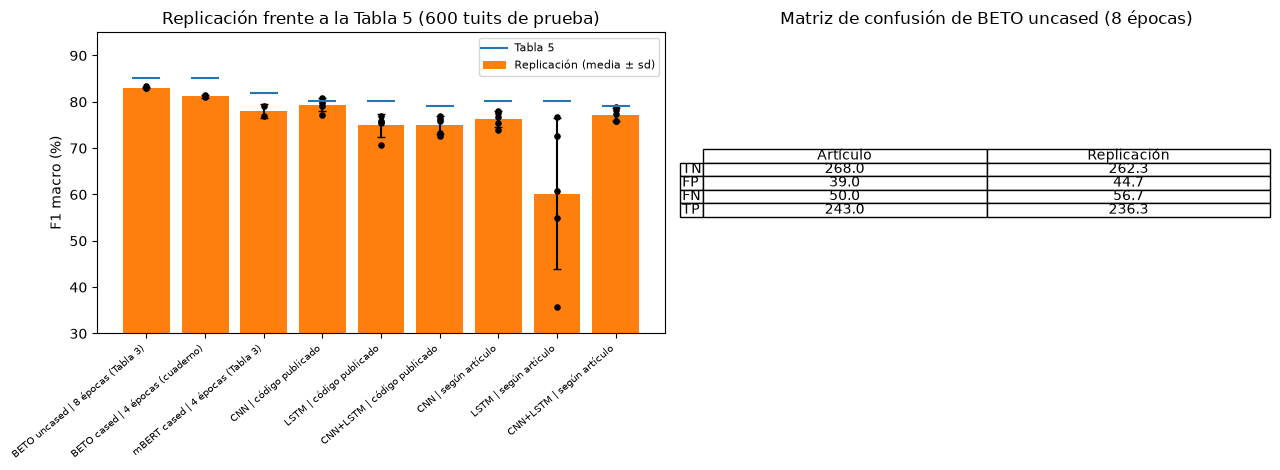

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
etiquetas = list(resumen.index)
x = np.arange(len(etiquetas))
axes[0].bar(x, resumen["F1_macro"], yerr=resumen["sd"].fillna(0), capsize=3, color="tab:orange", label="Replicación (media ± sd)")
for i, m in enumerate(etiquetas):
    pts = todo[todo.modelo == m]["F1_macro"]
    axes[0].scatter(np.full(len(pts), i), pts, s=14, color="black", zorder=3)
axes[0].scatter(x, [TABLA5.loc[ref[m], "F1_macro"] for m in etiquetas], marker="_", s=400, color="tab:blue", zorder=4, label="Tabla 5")
axes[0].set_xticks(x); axes[0].set_xticklabels(etiquetas, rotation=40, ha="right", fontsize=7)
axes[0].set_ylabel("F1 macro (%)"); axes[0].set_ylim(30, 95)
axes[0].set_title("Replicación frente a la Tabla 5 (600 tuits de prueba)"); axes[0].legend(fontsize=8)

cm_rep = todo[todo.modelo == "BETO uncased | 8 épocas (Tabla 3)"][["TN", "FP", "FN", "TP"]].mean().to_numpy().reshape(2, 2)
for k, (m, titulo) in enumerate([(FIG6_BETO, "Artículo (Figura 6)"), (cm_rep, "Replicación (media de semillas)")]):
    pass
axes[1].axis("off")
tabla_cm = pd.DataFrame({"Artículo": FIG6_BETO.ravel(), "Replicación": np.round(cm_rep.ravel(), 1)}, index=["TN", "FP", "FN", "TP"])
axes[1].table(cellText=tabla_cm.values, rowLabels=tabla_cm.index, colLabels=tabla_cm.columns, loc="center", cellLoc="center")
axes[1].set_title("Matriz de confusión de BETO uncased (8 épocas)")
plt.tight_layout(); plt.savefig(SALIDAS / "fig_replicacion_vs_articulo.png", dpi=150)
print("Figura guardada en:", SALIDAS / "fig_replicacion_vs_articulo.png")

Figura guardada en: salidas_71/fig_curvas_replicacion.png


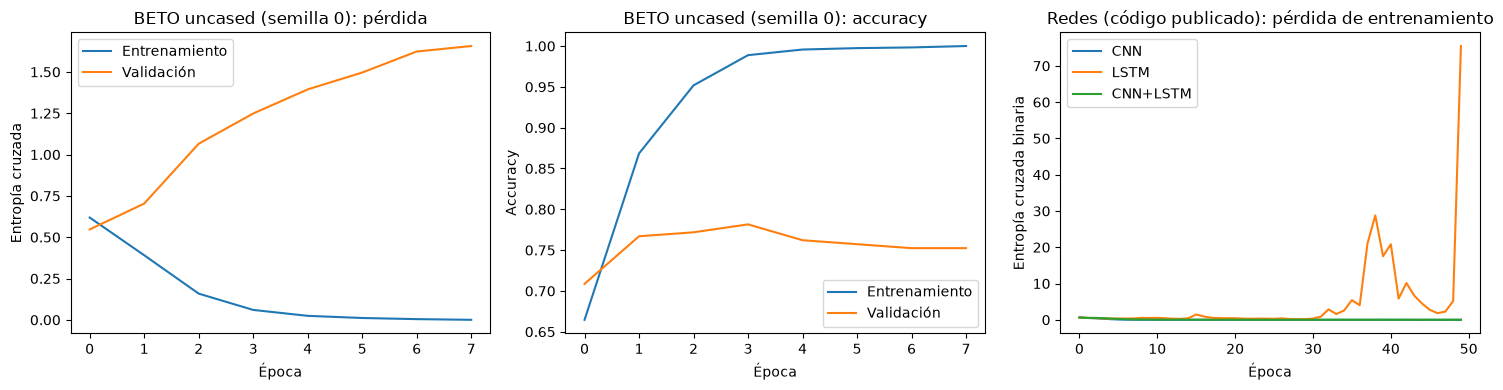

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(hist_val["loss"], label="Entrenamiento"); axes[0].plot(hist_val["val_loss"], label="Validación")
axes[0].set_title("BETO uncased (semilla 0): pérdida"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("Entropía cruzada"); axes[0].legend()
axes[1].plot(hist_val["accuracy"], label="Entrenamiento"); axes[1].plot(hist_val["val_accuracy"], label="Validación")
axes[1].set_title("BETO uncased (semilla 0): accuracy"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
for nombre in ["CNN | código publicado", "LSTM | código publicado", "CNN+LSTM | código publicado"]:
    axes[2].plot(curvas_redes[nombre]["loss"], label=nombre.split(" | ")[0])
axes[2].set_title("Redes (código publicado): pérdida de entrenamiento"); axes[2].set_xlabel("Época"); axes[2].set_ylabel("Entropía cruzada binaria"); axes[2].legend()
plt.tight_layout(); plt.savefig(SALIDAS / "fig_curvas_replicacion.png", dpi=150)
print("Figura guardada en:", SALIDAS / "fig_curvas_replicacion.png")

## 10. Conclusiones de la replicación

**¿Se reprodujo el método?** El flujo completo se reprodujo: el preprocesamiento y la partición coinciden con los números de los cuadernos de los autores (1,400 / 600 tuits; 1,369 / 589 sin duplicados; mismas secuencias), los embeddings originales cubren el 82.83 % del vocabulario (autores: 82.84 %) y todos los modelos se entrenaron con sus hiperparámetros documentados. Las métricas se reprodujeron con diferencias de entre 0.8 y 5.4 puntos según el modelo (tabla de la sección 9), no de 30 a 48 puntos como en la entrega anterior.

**¿Por qué las réplicas anteriores fallaron?** Eran fallas de implementación, no comportamiento real del método: (1) en mBERT, la optimización sin *warm-up* ni recorte hace que el entrenamiento no avance (F1 de 33.85 %, igual al de un predictor constante), (2) en las redes, los embeddings entrenados desde cero reemplazaron a los preentrenados y la LSTM con la arquitectura de la figura es inestable según la semilla (de 35.7 % a 76.8 %).

**¿Por qué quedan brechas respecto de la Tabla 5?** Son hipótesis, no resultados comprobados: (a) el artículo reporta una sola ejecución sin variabilidad, y los propios cuadernos de los autores no alcanzan sus cifras (BETO 80.5 %, mBERT 79.3 %, LSTM 76 %); (b) las arquitecturas del artículo y las del código no coinciden, y los hiperparámetros de la Tabla 4 (lote 32/64) tampoco coinciden con el código (lote 100); (c) la partición no estratificada tiene 39 textos repetidos entre entrenamiento y prueba y los cuadernos evalúan sobre 589 y no 600 tuits; (d) el código usa el conjunto de prueba como `validation_data`; (e) los autores hicieron una búsqueda de hiperparámetros con `RandomizedSearchCV` cuyo resultado final se perdió al reportarse solo la mejor corrida.

**Límites.** BETO uncased se evaluó con 3 semillas y BETO cased y mBERT con 2, por costo computacional, así que la variabilidad de estas dos últimas es solo indicativa. No se hizo búsqueda de hiperparámetros, a propósito, para no ajustar los resultados a los publicados. Las corridas «plana» y «con validación» son de una sola semilla.

---
# **Fase 2 · 7.2 Traslado al problema local**

Con el método verificado en 7.1, se aplica ahora al problema local: detectar mensajes racistas en comentarios en español dirigidos a medios latinoamericanos, con el corpus independiente *Contextualized Hate Speech* (Pérez et al., 2023; Hugging Face, `piuba-bigdata/contextualized_hate_speech`) y la etiqueta binaria `RACISM`. Esta sección documenta **qué se adapta y por qué**, deja una **partición única y congelada** y verifica con una primera aplicación que el flujo adaptado funciona. La comparación sistemática entre extractor congelado y *fine-tuning* es la sección 7.3, y la evaluación final contra la línea base en el conjunto de prueba, la 7.4.

| Aspecto | En el artículo / en 7.1 | En el traslado local | Motivo |
|---|---|---|---|
| Datos | 2,000 tuits, 48.6 % positivos, recolectados con palabras clave | 54,442 tuits depurados, 4.3 % positivos, respuestas a cinco medios argentinos | Cambio de fuente, país, anotación y prevalencia |
| Preparación del texto | `clean_tweet` (sin acentos, sin *stopwords*, sin menciones) | Normalización mínima (sección 3) | Se decide con evidencia de validación |
| Representación | BETO uncased, longitud máxima 128 | BETO uncased, longitud máxima 64 | Textos más cortos (mediana de 66 caracteres) |
| Desbalance | Casi balanceado | Submuestreo de negativos 5:1 solo en entrenamiento; validación y prueba conservan la prevalencia real | Costo de cómputo y señal de la clase minoritaria |
| Partición | 70/30 aleatoria, sin estratificar | 70/15/15 estratificada y **agrupada por noticia** | Evitar fuga entre comentarios de una misma noticia |
| Esquema de entrenamiento | 8 épocas fijas, lote 8 | Hasta 3 épocas, lote 16, mejor época por pérdida de validación | En 7.1 la pérdida de validación fue mínima en las primeras épocas y luego creció |

In [4]:
import os, sys, json, time, re, hashlib, subprocess
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_recall_fscore_support)

SALIDAS = Path("salidas_71"); SALIDAS.mkdir(exist_ok=True)
SEED = 42
REPO_ID = "piuba-bigdata/contextualized_hate_speech"
REVISION = "01aa9dcf5cdf81c14b412bf1b9c5e6b5fba9f98d"   # versión fija del corpus

## 1. Corpus local y flujo de preparación

Se parte de los tres archivos oficiales del corpus (entrenamiento, desarrollo y prueba), que se **unen** porque su partición oficial no es adecuada (se muestra en la sección 2), y se depura en dos pasos: se eliminan los textos duplicados con etiquetas contradictorias (son ambiguos) y luego los textos repetidos. La comparación se hace sobre el texto normalizado (minúsculas, menciones y enlaces reemplazados), de modo que un retuit o una respuesta idéntica salgan una sola vez. El resultado es **un único corpus final**; las cifras de 2,457 y 8,997 tuits de la entrega anterior no corresponden a este flujo y se descartan.

In [5]:
partes = []
for nombre in ["train", "dev", "test"]:
    ruta = hf_hub_download(repo_id=REPO_ID, filename=f"data/{nombre}-00000-of-00001.parquet",
                           repo_type="dataset", revision=REVISION)
    partes.append(pd.read_parquet(ruta, columns=["id", "title", "text", "RACISM"]).assign(particion_oficial=nombre))
corpus = pd.concat(partes, ignore_index=True)

def normalizar(s):
    s = s.str.lower()
    s = s.str.replace(r"@\w+", "@usuario", regex=True)
    s = s.str.replace(r"https?://\S+", "url", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

corpus["texto_norm"] = normalizar(corpus["text"])
contradictorios = corpus.groupby("texto_norm")["RACISM"].nunique()
contradictorios = contradictorios[contradictorios > 1].index

paso1 = corpus[~corpus["texto_norm"].isin(contradictorios)]
paso2 = paso1.drop_duplicates(subset="texto_norm", keep="first").reset_index(drop=True)
corpus_local = paso2.copy()

flujo = pd.DataFrame({
    "paso": ["Corpus completo (3 archivos oficiales)", "Sin textos con etiquetas contradictorias",
             "Sin textos repetidos = corpus local final"],
    "tuits": [len(corpus), len(paso1), len(paso2)],
    "positivos (RACISM = 1)": [int(corpus.RACISM.sum()), int(paso1.RACISM.sum()), int(paso2.RACISM.sum())],
})
flujo["% positivos"] = (100 * flujo["positivos (RACISM = 1)"] / flujo["tuits"]).round(2)
print(flujo.to_string(index=False))
print(f"\nTextos contradictorios: {len(contradictorios)} (filas eliminadas: {len(corpus) - len(paso1)})")
print(f"Textos repetidos eliminados: {len(paso1) - len(paso2)}")
print(f"\nCORPUS LOCAL FINAL: {len(corpus_local):,} tuits | positivos: {int(corpus_local.RACISM.sum()):,} "
      f"({100 * corpus_local.RACISM.mean():.2f} %) | noticias: {corpus_local.title.nunique():,}")

                                     paso  tuits  positivos (RACISM = 1)  % positivos
   Corpus completo (3 archivos oficiales)  56869                    2469         4.34
 Sin textos con etiquetas contradictorias  56765                    2432         4.28
Sin textos repetidos = corpus local final  54442                    2361         4.34

Textos contradictorios: 24 (filas eliminadas: 104)
Textos repetidos eliminados: 2323

CORPUS LOCAL FINAL: 54,442 tuits | positivos: 2,361 (4.34 %) | noticias: 1,235


**Lectura.** El flujo deja **un único corpus final de 54,442 tuits** (2,361 positivos, 4.34 %, 1,235 noticias). El paso de textos contradictorios elimina 104 filas (24 textos) y el de repetidos, 2,323. La proporción de positivos no cambia con la depuración (4.34 % antes y después), de modo que depurar no sesga la clase de interés.

## 2. Partición 70/15/15 sin fuga de información

El corpus no tiene fecha, así que **no hay orden cronológico que preservar**; el riesgo de fuga viene de dos fuentes: (1) los comentarios a una misma noticia se parecen entre sí, y (2) los mensajes casi idénticos (consignas repetidas) pueden caer en particiones distintas. La partición oficial no los controla: la validación comparte con el entrenamiento todas sus noticias. Por eso se vuelve a particionar con `StratifiedGroupKFold` (20 pliegues, semilla 42), agrupando por noticia y estratificando por `RACISM`: 14 pliegues forman el entrenamiento (70 %), 3 la validación (15 %) y 3 la prueba (15 %). El resultado es idéntico al de la corrección de la Fase 1, lo que permite comparar con la línea base ya construida.

In [6]:
kf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
pliegue = np.zeros(len(corpus_local), dtype=int)
for i, (_, idx) in enumerate(kf.split(corpus_local, corpus_local["RACISM"], groups=corpus_local["title"])):
    pliegue[idx] = i
corpus_local["particion"] = np.select([pliegue < 14, pliegue < 17], ["train", "val"], default="test")

tabla_part = corpus_local.groupby("particion").agg(
    tuits=("RACISM", "size"), positivos=("RACISM", "sum"), noticias=("title", "nunique")).loc[["train", "val", "test"]]
tabla_part["% del total"] = (100 * tabla_part["tuits"] / len(corpus_local)).round(1)
tabla_part["% positivos"] = (100 * tabla_part["positivos"] / tabla_part["tuits"]).round(2)
print(tabla_part.to_string())

# Comprobaciones de ausencia de fuga
en_varias = (corpus_local.groupby("title")["particion"].nunique() > 1).sum()
repetidos = corpus_local["texto_norm"].duplicated().sum()
print(f"\nNoticias presentes en más de una partición: {en_varias}")
print(f"Textos normalizados repetidos entre particiones: {repetidos}")

# Partición oficial, para contraste
of = corpus.drop_duplicates("texto_norm").copy()
tit = {p: set(of.loc[of.particion_oficial == p, "title"]) for p in ["train", "dev", "test"]}
print(f"Partición oficial: noticias de 'dev' que están también en 'train': {len(tit['dev'] & tit['train'])} de {len(tit['dev'])}")

# Partición congelada: se guarda con una huella para detectar cambios
corpus_local[["id", "particion"]].to_csv(SALIDAS / "particion_local.csv", index=False)
huella = hashlib.sha256("".join(map(str, sorted(corpus_local.loc[corpus_local.particion == "test", "id"]))).encode()).hexdigest()[:16]
print(f"\nConjunto de prueba congelado: {int((corpus_local.particion == 'test').sum())} tuits | huella SHA-256 de sus identificadores: {huella}")

           tuits  positivos  noticias  % del total  % positivos
particion                                                      
train      38065       1650       863         69.9         4.33
val         8202        356       187         15.1         4.34
test        8175        355       185         15.0         4.34

Noticias presentes en más de una partición: 0
Textos normalizados repetidos entre particiones: 0
Partición oficial: noticias de 'dev' que están también en 'train': 976 de 976

Conjunto de prueba congelado: 8175 tuits | huella SHA-256 de sus identificadores: a6919b60a4886b72


**Lectura.** Las tres particiones tienen la misma prevalencia (4.33-4.34 %) y **ninguna noticia ni texto se repite entre ellas**, por lo que los comentarios de una misma noticia no pueden estar a la vez en entrenamiento y evaluación. La partición oficial no sirve para validar: las 976 noticias de su archivo de desarrollo están también en el de entrenamiento. La prueba (8,175 tuits, 355 positivos) queda congelada y con una huella verificable (`a6919b60a4886b72`); no se usa hasta 7.4. Como el corpus no trae fecha, no hay orden cronológico que preservar.

**Casi duplicados.** La eliminación de repetidos exactos no detecta mensajes casi iguales («chinos de mierda» con pequeñas variantes). Se mide cuántos tuits de validación y prueba tienen un vecino casi idéntico en el entrenamiento (similitud coseno de TF-IDF); es un riesgo de fuga residual inherente al corpus que se reporta, no que se elimine.

In [7]:
tr = corpus_local[corpus_local.particion == "train"]
vec_sim = TfidfVectorizer(min_df=2, sublinear_tf=True).fit(tr["texto_norm"])
X_tr_sim = vec_sim.transform(tr["texto_norm"])

def max_similitud(textos):
    X = vec_sim.transform(textos); maximos = []
    for i in range(0, X.shape[0], 1000):
        S = X[i:i + 1000] @ X_tr_sim.T
        maximos.append(S.max(axis=1).toarray().ravel())
    return np.concatenate(maximos)

filas = []
for p in ["val", "test"]:
    sub = corpus_local[corpus_local.particion == p]
    sim = max_similitud(sub["texto_norm"])
    pos = sub["RACISM"].to_numpy() == 1
    filas.append({"partición": p, "tuits con vecino ≥ 0.9": f"{100 * (sim >= 0.9).mean():.1f} %",
                  "tuits con vecino ≥ 0.8": f"{100 * (sim >= 0.8).mean():.1f} %",
                  "positivos con vecino ≥ 0.9": f"{100 * (sim[pos] >= 0.9).mean():.1f} %"})
print(pd.DataFrame(filas).to_string(index=False))

partición tuits con vecino ≥ 0.9 tuits con vecino ≥ 0.8 positivos con vecino ≥ 0.9
      val                  6.8 %                  9.7 %                      5.3 %
     test                  7.2 %                  9.9 %                      6.5 %


**Lectura.** Entre el 6.8 % y el 7.2 % de los tuits de validación y prueba tienen un vecino casi idéntico (similitud ≥ 0.9) en el entrenamiento, y entre el 5.3 % y el 6.5 % de los positivos. Es una fuga residual propia del corpus (consignas repetidas con pequeñas variantes): puede favorecer levemente las métricas de cualquier modelo, afecta por igual a la línea base y a BETO, y se tendrá en cuenta al interpretar los resultados de 7.4.

## 3. Preparación del texto: qué cambia respecto del artículo

El `clean_tweet` del artículo elimina acentos, *stopwords* y menciones, decisiones pensadas para redes que usan el texto como bolsa de palabras. Para un modelo BERT conviene conservar la frase tal como está (negaciones, puntuación y acentos forman parte del contexto), pero se decide con evidencia: se compara, con la misma línea base TF-IDF + Regresión Logística y **solo sobre validación**, tres representaciones: el texto original, una normalización mínima (enlaces y menciones reemplazados por marcas) y el `clean_tweet` del artículo (definido en 7.1). Es un indicio con un modelo clásico, no una prueba para BETO.

In [8]:
def normalizacion_minima(s):
    s = s.str.replace(r"https?://\S+", " url ", regex=True)
    s = s.str.replace(r"@\w+", " usuario ", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

representaciones = {
    "texto original": lambda s: s,
    "normalización mínima": normalizacion_minima,
    "clean_tweet del artículo": lambda s: s.apply(clean_tweet),
}
y_tr = corpus_local.loc[corpus_local.particion == "train", "RACISM"].to_numpy()
y_va = corpus_local.loc[corpus_local.particion == "val", "RACISM"].to_numpy()
txt_tr = corpus_local.loc[corpus_local.particion == "train", "text"]
txt_va = corpus_local.loc[corpus_local.particion == "val", "text"]

def metricas_bin(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[1], zero_division=0)
    return {"F1 macro": f1_score(y, pred, average="macro"), "precisión (racista)": p[0],
            "recall (racista)": r[0], "F1 (racista)": f[0], "PR-AUC": average_precision_score(y, prob)}

filas = []
for nombre, f in representaciones.items():
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    A = vec.fit_transform(f(txt_tr)); B = vec.transform(f(txt_va))
    lr = LogisticRegression(C=10, class_weight="balanced", max_iter=2000, random_state=SEED).fit(A, y_tr)
    filas.append({"representación": nombre, **metricas_bin(y_va, lr.predict_proba(B)[:, 1])})
rep_tabla = pd.DataFrame(filas).set_index("representación")
print("Línea base TF-IDF + Regresión Logística, métricas en VALIDACIÓN\n")
print(rep_tabla.round(3).to_string())

Línea base TF-IDF + Regresión Logística, métricas en VALIDACIÓN

                          F1 macro  precisión (racista)  recall (racista)  F1 (racista)  PR-AUC
representación                                                                                 
texto original               0.756                0.474             0.618         0.537   0.572
normalización mínima         0.760                0.486             0.618         0.544   0.567
clean_tweet del artículo     0.742                0.420             0.657         0.513   0.530


**Lectura.** La normalización mínima obtiene el mejor F1 macro en validación (0.760, frente a 0.756 con el texto original y 0.742 con el `clean_tweet` del artículo), y `clean_tweet` empeora la precisión de la clase racista (0.420 frente a 0.486). La diferencia entre las dos primeras es pequeña (0.004), así que no hay evidencia de que el preprocesamiento del artículo ayude y sí de que perjudica algo; se adopta la normalización mínima, que además conserva el contexto que BERT utiliza. Es un indicio con un modelo clásico, no una prueba para BETO.

## 4. Representación de la entrada y esquema de entrenamiento

**Longitud.** Se mide la longitud en tokens de BETO para fijar el máximo. **Desbalance.** Con 4.3 % de positivos, entrenar sobre las 38,065 filas cuesta unos 40 minutos por época sin aportar más señal de la clase minoritaria. En el entrenamiento se conservan todos los positivos y 5 negativos por positivo (submuestreo aleatorio con semilla); **validación y prueba conservan la prevalencia real**, que es la que se enfrentará en uso. El submuestreo desplaza la probabilidad predicha, por lo que el umbral de decisión se elige sobre validación, y no se asume 0.5.

In [9]:
from transformers import AutoTokenizer
tok_beto = AutoTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-uncased")
muestra = txt_tr.sample(3000, random_state=SEED).pipe(normalizacion_minima)
largos = np.array([len(x) for x in tok_beto(muestra.tolist(), add_special_tokens=True)["input_ids"]])
print("Longitud en tokens de BETO (muestra de 3,000 tuits de entrenamiento):")
print({f"p{q}": int(np.percentile(largos, q)) for q in (50, 90, 95, 99)}, "| máximo:", int(largos.max()))
MAX_LEN = 64
print(f"Tuits que se truncarían con max_len = {MAX_LEN}: {100 * (largos > MAX_LEN).mean():.2f} %")

rng = np.random.RandomState(SEED)
idx_pos = np.where(y_tr == 1)[0]; idx_neg = np.where(y_tr == 0)[0]
idx_neg_sel = rng.choice(idx_neg, size=5 * len(idx_pos), replace=False)
idx_ent = rng.permutation(np.concatenate([idx_pos, idx_neg_sel]))
txt_ent = normalizacion_minima(txt_tr.reset_index(drop=True)).iloc[idx_ent].tolist()
y_ent = y_tr[idx_ent].tolist()
print(f"\nEntrenamiento original: {len(y_tr):,} tuits ({100 * y_tr.mean():.1f} % positivos)")
print(f"Entrenamiento tras el submuestreo: {len(y_ent):,} tuits ({100 * np.mean(y_ent):.1f} % positivos)")

json.dump({"train_text": txt_ent, "train_y": y_ent,
           "eval_text": normalizacion_minima(txt_va.reset_index(drop=True)).tolist(), "eval_y": y_va.tolist()},
          open(SALIDAS / "datos_local.json", "w", encoding="utf-8"))

Longitud en tokens de BETO (muestra de 3,000 tuits de entrenamiento):
{'p50': 17, 'p90': 45, 'p95': 56, 'p99': 68} | máximo: 85
Tuits que se truncarían con max_len = 64: 2.03 %

Entrenamiento original: 38,065 tuits (4.3 % positivos)
Entrenamiento tras el submuestreo: 9,900 tuits (16.7 % positivos)


**Lectura.** La mediana es de 17 tokens y el percentil 99, de 68. Con una longitud máxima de 64 solo se trunca el 2.03 % de los tuits (el artículo usa 128), con menos cómputo y sin pérdida apreciable. El submuestreo deja 9,900 tuits de entrenamiento con 16.7 % de positivos.

## 5. Primera aplicación del método al corpus local

Se ajusta BETO uncased de forma completa (el método del artículo) con las adaptaciones anteriores: longitud 64, lote 16, tasa de aprendizaje de 4e-5 con *warm-up* del 6 % y decaimiento lineal, recorte de gradiente a 1.0 y hasta 3 épocas. Como en 7.1, cada corrida se ejecuta en un proceso aparte (el plugin de GPU de Metal acumula memoria). Al final de cada época se evalúa **solo la validación**; la época se elige por la pérdida de validación. **El conjunto de prueba no se toca en esta sección.**

In [10]:
%%writefile bert_worker_local.py
# Entrena BETO sobre el corpus local y guarda, por época, los logits de validación.
import os, sys, json, time, random
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
import tf_keras
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification


def entrenar(a):
    semilla = a["semilla"]
    os.environ["PYTHONHASHSEED"] = str(semilla)
    random.seed(semilla); np.random.seed(semilla); tf.random.set_seed(semilla)
    datos = json.load(open(a["datos"], encoding="utf-8"))
    textos, y = datos["train_text"], np.array(datos["train_y"])
    ev_txt, ev_y = datos["eval_text"], np.array(datos["eval_y"])

    tok = AutoTokenizer.from_pretrained(a["checkpoint"])
    modelo = TFAutoModelForSequenceClassification.from_pretrained(a["checkpoint"], num_labels=2)
    n, lote, epocas = len(textos), a["lote"], a["epocas"]
    total = int(np.ceil(n / lote)) * epocas
    pasos_warm = int(a["warmup"] * total)
    lr = a["lr"]
    lr_var = tf.Variable(lr, trainable=False, dtype=tf.float32)
    opt = tf_keras.optimizers.legacy.Adam(learning_rate=lr_var, epsilon=1e-8)
    perdida = tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True)

    def tasa(paso):
        if paso < pasos_warm:
            return lr * paso / max(1, pasos_warm)
        return lr * max(0.0, (total - paso) / max(1, total - pasos_warm))

    @tf.function(reduce_retracing=True)
    def paso_entrenamiento(entrada, etiquetas):
        with tf.GradientTape() as cinta:
            logits = modelo(entrada, training=True).logits
            l = perdida(etiquetas, logits)
        grads = cinta.gradient(l, modelo.trainable_variables)
        grads, _ = tf.clip_by_global_norm(grads, a["recorte"])
        opt.apply_gradients(zip(grads, modelo.trainable_variables))
        return l

    def lotes(txt, tam, orden=None):
        idx = np.arange(len(txt)) if orden is None else orden
        for i in range(0, len(idx), tam):
            b = idx[i:i + tam]
            enc = tok([txt[j] for j in b], padding=True, pad_to_multiple_of=16, truncation=True,
                      max_length=a["max_len"], return_tensors="tf")
            yield b, dict(enc)

    def predecir(txt):
        return np.concatenate([modelo(enc, training=False).logits.numpy() for _, enc in lotes(txt, 64)])

    hist = {"loss": [], "val_loss": []}
    rng = np.random.RandomState(semilla); paso = 0; t0 = time.time()
    for ep in range(epocas):
        orden = rng.permutation(n); perd = []
        for b, enc in lotes(textos, lote, orden):
            lr_var.assign(tasa(paso)); paso += 1
            perd.append(float(paso_entrenamiento(enc, tf.constant(y[b]))) * len(b))
        lg = predecir(ev_txt)
        np.save(f"{a['salida']}_val_logits_ep{ep + 1}.npy", lg)
        hist["loss"].append(sum(perd) / n)
        hist["val_loss"].append(float(perdida(ev_y, lg)))
        with open(a["log"], "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} local {a['etiqueta']} época {ep + 1}/{epocas} "
                    f"pérdida {hist['loss'][-1]:.4f} pérdida val {hist['val_loss'][-1]:.4f}\n")
    return hist, time.time() - t0


if __name__ == "__main__":
    a = json.loads(sys.argv[1])
    hist, seg = entrenar(a)
    json.dump({"hist": hist, "segundos": seg}, open(a["salida"] + ".json", "w"))

Writing bert_worker_local.py


In [11]:
RUNS = SALIDAS / "corridas_local"; RUNS.mkdir(exist_ok=True)
EPOCAS_LOCAL = 3
etiqueta = f"beto_uncased_local_ep{EPOCAS_LOCAL}_s0"
salida = RUNS / etiqueta
if not salida.with_suffix(".json").exists():
    args = dict(checkpoint="dccuchile/bert-base-spanish-wwm-uncased", epocas=EPOCAS_LOCAL, semilla=0, lr=4e-5, lote=16,
                warmup=0.06, recorte=1.0, max_len=MAX_LEN, datos=str(SALIDAS / "datos_local.json"),
                log=str(SALIDAS / "progreso_bert.log"), etiqueta=etiqueta, salida=str(salida))
    r = subprocess.run([sys.executable, "bert_worker_local.py", json.dumps(args)], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])
res_local = json.load(open(salida.with_suffix(".json")))
hist_local = pd.DataFrame(res_local["hist"], index=range(1, EPOCAS_LOCAL + 1)).rename_axis("época")
print(hist_local.round(4).to_string())

         loss  val_loss
época                  
1      0.2991    0.2111
2      0.1749    0.2206
3      0.0843    0.2240


**Lectura.** La pérdida de entrenamiento baja en las tres épocas (0.299, 0.175 y 0.084), pero la de validación es mínima en la **época 1** (0.211) y sube a 0.221 y 0.224: hay sobreajuste desde la segunda época, igual que en la réplica de 7.1. Por eso se usa la época 1, elegida solo con validación. No se reporta el tiempo de entrenamiento porque el reloj del proceso incluyó periodos de suspensión del equipo; por el ritmo de 7.1 (≈ 0.8 s por paso) corresponde a unos 30 minutos.

## 6. Evaluación en validación y contexto frente a la línea base

Se elige la época con menor pérdida de validación y se reportan las métricas de la clase racista en validación con el umbral 0.5 y con el umbral que maximiza el F1 de la clase racista **en validación** (optimista allí, porque se elige con esos mismos datos; en 7.4 se aplicará congelado al conjunto de prueba). Se incluye la línea base TF-IDF + Regresión Logística de la Fase 1, reentrenada con la representación elegida, **sobre exactamente las mismas observaciones de validación**. Esta comparación es una verificación del flujo y no un dictamen: el dictamen se hace en el conjunto de prueba (7.4).

VALIDACIÓN: 8,202 tuits, 356 racistas (4.34 %)

                                                F1 macro  precisión (racista)  recall (racista)  F1 (racista)  PR-AUC
modelo                  umbral                                                                                       
BETO uncased (época 1)  0.5                        0.732                0.363             0.815         0.503   0.484
                        0.951 (óptimo en val.)     0.786                0.542             0.654         0.593   0.484
TF-IDF + Reg. Logística 0.5                        0.760                0.486             0.618         0.544   0.567
                        0.647 (óptimo en val.)     0.774                0.577             0.556         0.567   0.567


Figura guardada en: salidas_71/fig_traslado_local.png


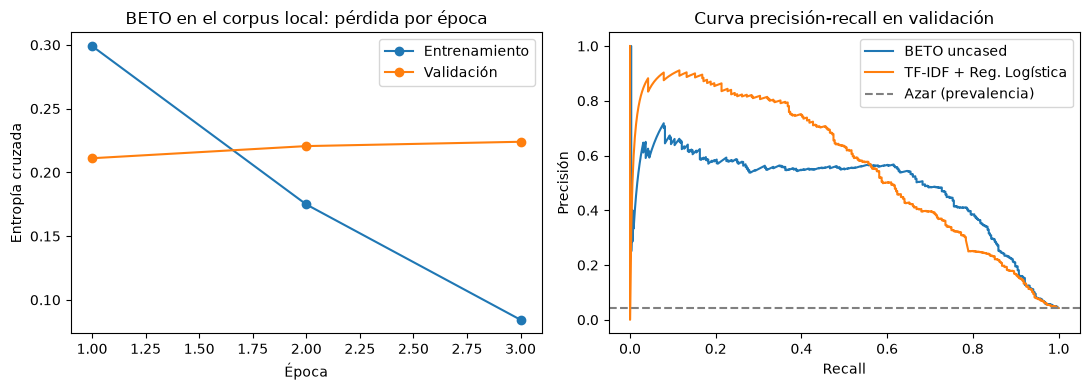

In [12]:
mejor_ep = int(hist_local["val_loss"].idxmin())
lg = np.load(f"{salida}_val_logits_ep{mejor_ep}.npy")
prob_beto = np.exp(lg[:, 1] - np.logaddexp(lg[:, 0], lg[:, 1]))

def mejor_umbral(y, prob):
    p, r, t = precision_recall_curve(y, prob)
    f = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    return float(t[np.argmax(f)])

REP = "normalización mínima"          # representación usada en el modelo local (sección 3)
vec_b = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
A = vec_b.fit_transform(representaciones[REP](txt_tr)); B = vec_b.transform(representaciones[REP](txt_va))
lr_b = LogisticRegression(C=10, class_weight="balanced", max_iter=2000, random_state=SEED).fit(A, y_tr)
prob_lr = lr_b.predict_proba(B)[:, 1]

filas = []
for nombre, prob in [("BETO uncased (época %d)" % mejor_ep, prob_beto), ("TF-IDF + Reg. Logística", prob_lr)]:
    u = mejor_umbral(y_va, prob)
    filas.append({"modelo": nombre, "umbral": "0.5", **metricas_bin(y_va, prob, 0.5)})
    filas.append({"modelo": nombre, "umbral": f"{u:.3f} (óptimo en val.)", **metricas_bin(y_va, prob, u)})
tabla_val = pd.DataFrame(filas).set_index(["modelo", "umbral"])
print(f"VALIDACIÓN: {len(y_va):,} tuits, {int(y_va.sum())} racistas ({100 * y_va.mean():.2f} %)\n")
print(tabla_val.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist_local.index, hist_local["loss"], marker="o", label="Entrenamiento")
axes[0].plot(hist_local.index, hist_local["val_loss"], marker="o", label="Validación")
axes[0].set_title("BETO en el corpus local: pérdida por época"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("Entropía cruzada"); axes[0].legend()
for nombre, prob in [("BETO uncased", prob_beto), ("TF-IDF + Reg. Logística", prob_lr)]:
    p, r, _ = precision_recall_curve(y_va, prob); axes[1].plot(r, p, label=nombre)
axes[1].axhline(y_va.mean(), color="gray", linestyle="--", label="Azar (prevalencia)")
axes[1].set_title("Curva precisión-recall en validación"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precisión"); axes[1].legend()
plt.tight_layout(); plt.savefig(SALIDAS / "fig_traslado_local.png", dpi=150)
print("Figura guardada en:", SALIDAS / "fig_traslado_local.png")

In [13]:
u = mejor_umbral(y_va, prob_beto)
cm = confusion_matrix(y_va, (prob_beto >= u).astype(int))
cm_lr = confusion_matrix(y_va, (prob_lr >= mejor_umbral(y_va, prob_lr)).astype(int))
print("Matrices de confusión en validación, con el umbral óptimo de cada modelo [[TN, FP], [FN, TP]]:")
print("BETO uncased:", cm.tolist(), "| TF-IDF + Reg. Logística:", cm_lr.tolist())

Matrices de confusión en validación, con el umbral óptimo de cada modelo [[TN, FP], [FN, TP]]:
BETO uncased: [[7649, 197], [123, 233]] | TF-IDF + Reg. Logística: [[7701, 145], [158, 198]]


**Lectura (validación; no es un dictamen).** Con el umbral 0.5, BETO tiene un recall alto (0.815) pero una precisión baja (0.363): el submuestreo (16.7 % de positivos en entrenamiento frente al 4.3 % real) lo lleva a sobrepredecir la clase racista. La línea base, entrenada con la prevalencia real y pesos de clase, está más equilibrada (precisión 0.486, recall 0.618). Con el umbral que maximiza el F1 de la clase racista en validación, BETO llega a F1 macro de 0.786 y F1 de la clase racista de 0.593 (precisión 0.542, recall 0.654), frente a 0.774 y 0.567 de la línea base (0.577 y 0.556). Las matrices lo reflejan: BETO detecta 233 de 356 mensajes racistas con 197 falsos positivos, y la línea base 198 con 145.

Estos números no permiten concluir todavía: (1) los umbrales se eligieron sobre esta misma validación, por lo que son optimistas; (2) el PR-AUC de BETO (0.484) es **menor** que el de la línea base (0.567), es decir, el orden de las probabilidades de BETO no es mejor que el de TF-IDF, así que la ventaja a un umbral dado puede no sostenerse en otros umbrales ni en la prueba; (3) es una sola semilla, una sola época y una sola configuración (ajuste completo). La comparación con más semillas y variantes (7.3) y sobre la prueba congelada (7.4) es la que sostendrá cualquier conclusión.

## 7. Conclusiones del traslado (7.2)

- **Corpus único.** El corpus local final tiene 54,442 tuits, con 2,361 positivos (4.34 %) en 1,235 noticias; el flujo desde los 56,869 tuits del corpus original está documentado paso a paso (sección 1).
- **Adaptaciones.** Normalización mínima del texto en lugar del `clean_tweet` (decidida con evidencia de validación), longitud máxima de 64 tokens, submuestreo 5:1 de negativos solo en el entrenamiento, umbral de decisión elegido en validación y entrenamiento de hasta 3 épocas con la mejor época por pérdida de validación.
- **Partición sin fuga.** 70/15/15 estratificada y agrupada por noticia (38,065 / 8,202 / 8,175 tuits): 0 noticias y 0 textos compartidos entre particiones. Queda un riesgo residual de casi duplicados (≈ 7 %), que se reporta. La prueba está congelada (huella `a6919b60a4886b72`) y no se usó en esta sección.
- **Primera aplicación.** El método adaptado funciona: BETO aprende (la pérdida de validación es mínima en la época 1 y luego sube, por sobreajuste) y alcanza F1 macro de 0.732 con umbral 0.5 y 0.786 con el umbral óptimo en validación. El resultado es preliminar y no se compara aún de forma concluyente con la línea base.
- **Pendiente.** 7.3: contraste entre extractor congelado y *fine-tuning* parcial con varias semillas, con las tasas de aprendizaje y el criterio de parada explícitos. 7.4: evaluación de la línea base y de todas las variantes sobre el mismo conjunto de prueba, sin usarlo para elegir configuraciones.

**Límites.** Una sola semilla y una sola configuración; el submuestreo desplaza las probabilidades; la decisión sobre el preprocesamiento se tomó con un modelo clásico; y el corpus es argentino, de un solo periodo (pandemia) y con una etiqueta `RACISM` más amplia que la xenofobia hacia migrantes.

---
# **Fase 2 · 7.3 Estrategia de transferencia de aprendizaje**

Esta sección justifica las decisiones de transferencia y las **contrasta con evidencia** sobre el conjunto de validación del corpus local (la prueba sigue congelada). Se responde a cinco preguntas: qué modelo preentrenado se usa y por qué, qué distancia hay entre el dominio de preentrenamiento y el local, hasta dónde se descongelan las capas, con qué tasas de aprendizaje y bajo qué criterio de parada.

Se comparan **cuatro niveles de ajuste** con una sola variable cambiando (el número de capas del codificador que se entrenan) y todo lo demás constante: mismos datos de entrenamiento y validación (los de 7.2), misma partición, mismo tamaño de lote, mismo calendario de tasa de aprendizaje y mismo criterio de parada.

| Nivel | Capas del codificador entrenables | Tasa de aprendizaje del codificador | Tasa de aprendizaje de la cabeza | Parámetros entrenables |
|---|---|---|---|---|
| T0, extractor congelado | 0 de 12 (se usa el promedio de los vectores de la última capa) | no aplica | 1e-3 | 1,538 |
| T1, ajuste parcial | las 2 últimas | 3e-5 | 1e-3 | ≈ 14.8 M |
| T2, ajuste parcial | las 4 últimas | 3e-5 | 1e-3 | ≈ 28.9 M |
| T3, ajuste completo | las 12 + embeddings | 3e-5 | 1e-3 | ≈ 109.9 M |

**Tasas diferenciadas.** La cabeza de clasificación (y el *pooler*) se inicializa al azar y necesita una tasa alta (1e-3); las capas preentrenadas se ajustan con una tasa 30 veces menor (3e-5), para adaptar sin destruir lo aprendido. **Criterio de parada.** Hasta 3 épocas (30 para T0), y se detiene cuando la pérdida de validación no mejora respecto de la época anterior (paciencia 1; paciencia 3 en T0); se conserva la mejor época. Calendario común: *warm-up* del 6 % de los pasos, decaimiento lineal, recorte de gradiente a 1.0, lote 16 y longitud máxima 64.

**Regla de decisión fijada antes de ver los resultados:** se elige el nivel con mayor **PR-AUC medio en validación** (no depende del umbral, que se elige aparte); si la diferencia con otro nivel es menor que una desviación estándar, se prefiere el que entrena menos parámetros. La elección se congela y se evalúa una sola vez en el conjunto de prueba (7.4).

In [1]:
import os, sys, json, time, re, subprocess
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_recall_fscore_support, confusion_matrix)

SALIDAS = Path("salidas_71"); SALIDAS.mkdir(exist_ok=True)
SEED = 42
REPO_ID = "piuba-bigdata/contextualized_hate_speech"
REVISION = "01aa9dcf5cdf81c14b412bf1b9c5e6b5fba9f98d"
CHECKPOINT = "dccuchile/bert-base-spanish-wwm-uncased"

# Datos de entrenamiento (submuestreo 5:1) y de validación de la sección 7.2
datos = json.load(open(SALIDAS / "datos_local.json", encoding="utf-8"))
y_va = np.array(datos["eval_y"])
print(f"Entrenamiento: {len(datos['train_y']):,} tuits ({100 * np.mean(datos['train_y']):.1f} % positivos) | "
      f"validación: {len(y_va):,} tuits ({100 * y_va.mean():.2f} % positivos)")

def mejor_umbral(y, prob):
    p, r, t = precision_recall_curve(y, prob)
    f = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    return float(t[np.argmax(f)])

def metricas_val(y, prob):
    """Métricas sobre validación: independientes del umbral (PR-AUC) y con el umbral 0.5 y el óptimo en validación."""
    u = mejor_umbral(y, prob)
    out = {"PR-AUC": average_precision_score(y, prob)}
    for nombre, thr in (("0.5", 0.5), ("opt", u)):
        pred = (prob >= thr).astype(int)
        p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[1], zero_division=0)
        out.update({f"F1 macro @{nombre}": f1_score(y, pred, average="macro"), f"precisión @{nombre}": p[0],
                    f"recall @{nombre}": r[0], f"F1 racista @{nombre}": f[0]})
    out["umbral óptimo"] = u
    return out

# Línea base clásica de las secciones anteriores, para contexto (misma validación, mismas observaciones)
parquets = [pd.read_parquet(hf_hub_download(REPO_ID, f"data/{n}-00000-of-00001.parquet", repo_type="dataset", revision=REVISION),
                            columns=["id", "text"]) for n in ["train", "dev", "test"]]
todos = pd.concat(parquets).drop_duplicates("id")
part = pd.read_csv(SALIDAS / "particion_local.csv").merge(todos, on="id")
part["y"] = pd.concat([pd.read_parquet(hf_hub_download(REPO_ID, f"data/{n}-00000-of-00001.parquet", repo_type="dataset",
                       revision=REVISION), columns=["id", "RACISM"]) for n in ["train", "dev", "test"]]).drop_duplicates("id").set_index("id").loc[part["id"], "RACISM"].values
def normalizacion_minima(s):
    s = s.str.replace(r"https?://\S+", " url ", regex=True)
    s = s.str.replace(r"@\w+", " usuario ", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()
tr, va = part[part.particion == "train"], part[part.particion == "val"]
assert (va["y"].values == y_va).all(), "la validación no coincide con la de 7.2"
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
A = vec.fit_transform(normalizacion_minima(tr["text"])); B = vec.transform(normalizacion_minima(va["text"]))
prob_lr = LogisticRegression(C=10, class_weight="balanced", max_iter=2000, random_state=SEED).fit(A, tr["y"]).predict_proba(B)[:, 1]
m_lr = metricas_val(y_va, prob_lr)
print(f"\nLínea base TF-IDF + Regresión Logística en validación: PR-AUC = {m_lr['PR-AUC']:.3f} | "
      f"F1 racista (umbral óptimo) = {m_lr['F1 racista @opt']:.3f} | recall (umbral óptimo) = {m_lr['recall @opt']:.3f}")

Entrenamiento: 9,900 tuits (16.7 % positivos) | validación: 8,202 tuits (4.34 % positivos)



Línea base TF-IDF + Regresión Logística en validación: PR-AUC = 0.567 | F1 racista (umbral óptimo) = 0.567 | recall (umbral óptimo) = 0.556


## 1. Modelo preentrenado: BETO uncased

Se emplea **BETO uncased** (`dccuchile/bert-base-spanish-wwm-uncased`; Cañete et al., 2020), un BERT-base preentrenado solo con texto en español (Wikipedia, subtítulos y noticias). Las razones se apoyan en la evidencia de la sección 7.1, sobre tuits en español en una tarea idéntica (racismo/xenofobia):

- **Idioma:** BETO supera al modelo multilingüe mBERT en el corpus del artículo (F1 macro de 83.1 % frente a 78.1 %).
- **Capitalización:** en el mismo corpus, la versión *uncased* supera a la *cased* (83.1 % frente a 81.2 %), coherente con la informalidad de los tuits.
- **Continuidad:** es el modelo del artículo, de modo que el traslado se compara con lo ya replicado.

In [2]:
r = pd.read_csv(SALIDAS / "resumen_replicacion.csv", index_col=0)
print(r.loc[[i for i in r.index if i.startswith(("BETO", "mBERT"))], ["n", "F1_macro", "sd", "minimo", "maximo"]].round(2).to_string())

                                   n  F1_macro    sd  minimo  maximo
modelo                                                              
BETO uncased | 8 épocas (Tabla 3)  3     83.08  0.20   82.94   83.31
BETO cased | 4 épocas (cuaderno)   2     81.20  0.34   80.96   81.44
mBERT cased | 4 épocas (Tabla 3)   2     78.05  1.50   76.99   79.11


**Alternativa no evaluada.** Existen modelos preentrenados con tuits en español (por ejemplo, RoBERTuito), cuyo dominio de origen está más cerca del local. No se evalúan en esta entrega por costo de cómputo; se deja como línea de continuidad y como limitación (sección de conclusiones).

## 2. Distancia entre el dominio de preentrenamiento y el local

BETO se preentrenó con texto formal y de extensión media. Los comentarios del corpus local son cortos, coloquiales y con insultos. Para medir esa distancia sin inventar un corpus de referencia, se usa el propio corpus: cada comentario responde a una **noticia de prensa** (columna `body`), que es texto formal de un tipo cercano al de preentrenamiento de BETO. Se comparan, con el mismo tokenizador, las noticias y los comentarios: palabras partidas en varias subpalabras (señal de vocabulario poco familiar), tokens desconocidos y palabras de los comentarios que nunca aparecen en las noticias.

In [3]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(CHECKPOINT)
cuerpos = pd.read_parquet(hf_hub_download(REPO_ID, "data/train-00000-of-00001.parquet", repo_type="dataset", revision=REVISION),
                          columns=["title", "body"]).drop_duplicates("title")["body"].dropna()
noticias = cuerpos.sample(300, random_state=SEED).str.slice(0, 1500).tolist()
comentarios = pd.Series(datos["train_text"]).sample(3000, random_state=SEED).tolist()

def estadisticas(textos):
    palabras = [w for t in textos for w in re.findall(r"\w+", t.lower())]
    piezas = tok(palabras[:60000], add_special_tokens=False)["input_ids"]
    n = np.array([len(p) for p in piezas])
    return {"subpalabras por palabra": n.mean(), "% palabras en ≥ 3 subpalabras": 100 * (n >= 3).mean(),
            "% tokens desconocidos": 100 * np.mean([tok.unk_token_id in p for p in piezas]),
            "palabras distintas": len(set(palabras))}, set(palabras)

est_n, voc_n = estadisticas(noticias)
est_c, voc_c = estadisticas(comentarios)
tabla = pd.DataFrame({"noticias (formal)": est_n, "comentarios (local)": est_c})
print(tabla.round(2).to_string())
print(f"\nPalabras distintas de los comentarios que no aparecen en las noticias: {100 * len(voc_c - voc_n) / len(voc_c):.1f} %")

patrones = {"con insultos o groserías frecuentes": r"\b(mierda|puto|puta|hdp|conchudo|boludo)\b", "con risas (jaja)": r"ja(ja)+|jeje",
            "con letras repetidas (¡noooo!)": r"(\w)\1{2,}", "con emojis": "[\U0001F300-\U0001FAFF☀-➿]", "en mayúsculas ≥ 50 %": None}
filas = {}
for nombre, p in patrones.items():
    if p is None:
        filas[nombre] = 100 * np.mean([sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t)) >= 0.5 for t in comentarios])
    else:
        filas[nombre] = 100 * np.mean([bool(re.search(p, t.lower())) for t in comentarios])
print("\nRasgos de registro informal en los comentarios (% de tuits):")
print(pd.Series(filas).round(1).to_string())

                               noticias (formal)  comentarios (local)
subpalabras por palabra                     1.12                 1.17
% palabras en ≥ 3 subpalabras               2.52                 3.28
% tokens desconocidos                       0.01                 0.08
palabras distintas                      10980.00              8233.00

Palabras distintas de los comentarios que no aparecen en las noticias: 59.3 %

Rasgos de registro informal en los comentarios (% de tuits):
con insultos o groserías frecuentes    6.8
con risas (jaja)                       3.3
con letras repetidas (¡noooo!)         4.2
con emojis                             8.2
en mayúsculas ≥ 50 %                   3.5


**Lectura.** La distancia es **moderada y sobre todo léxica**. En tokenización los comentarios se parecen bastante a las noticias: 1.17 subpalabras por palabra frente a 1.12, 3.3 % de palabras partidas en 3 o más subpalabras (2.5 % en noticias) y 0.08 % de tokens desconocidos (0.01 %), así que el vocabulario de BETO cubre bien el español de los comentarios. Lo que cambia es el vocabulario y el registro: el 59.3 % de las palabras distintas de los comentarios no aparece en la muestra de noticias (cifra inflada por el tamaño de esa muestra, 300 noticias) y una fracción pequeña pero real de los tuits trae insultos (6.8 %), emojis (8.2 %) o letras repetidas (4.2 %). Además, BETO nunca vio la distinción entre mensajes racistas y no racistas. Esto anticipa que entrenar solo una cabeza sobre vectores congelados será insuficiente, hipótesis que se contrasta a continuación.

## 3. Experimento: cuánto descongelar

Se entrena cada nivel con las mismas condiciones y se evalúa **solo en validación**. T0 usa 3 semillas (es barato) y T1, T2 y T3, 2 semillas cada uno por costo computacional, de modo que la variabilidad de T1-T3 es solo indicativa. Cada corrida se ejecuta en un proceso aparte (por la acumulación de memoria del plugin de GPU de Metal, como en 7.1) y queda guardada en `salidas_71/corridas_transfer/`; el tiempo por paso se mide con la mediana de los pasos, que no se altera si el equipo se suspende.

In [4]:
%%writefile bert_worker_transfer.py
# Una corrida de transferencia (T0-T3) sobre el corpus local; guarda los logits de validación de la mejor época.
import os, sys, json, time, random
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
import tf_keras
from transformers import AutoTokenizer, TFAutoModel, TFAutoModelForSequenceClassification


def lotes(tok, txt, tam, max_len, orden=None):
    idx = np.arange(len(txt)) if orden is None else orden
    for i in range(0, len(idx), tam):
        b = idx[i:i + tam]
        enc = tok([txt[j] for j in b], padding=True, pad_to_multiple_of=16, truncation=True, max_length=max_len, return_tensors="tf")
        yield b, dict(enc)


def correr_t0(a, datos, tok, perdida):
    """Extractor congelado: promedio de los vectores de la última capa (BETO en modo inferencia) + cabeza lineal."""
    rutas = {k: f"{a['features']}_{k}.npy" for k in ("train", "val")}
    if not all(os.path.exists(r) for r in rutas.values()):
        bert = TFAutoModel.from_pretrained(a["checkpoint"])
        for k, txt in (("train", datos["train_text"]), ("val", datos["eval_text"])):
            fs = []
            for _, enc in lotes(tok, txt, 64, a["max_len"]):
                h = bert(enc, training=False).last_hidden_state.numpy()
                m = enc["attention_mask"].numpy()[..., None]
                fs.append((h * m).sum(1) / m.sum(1))
            np.save(rutas[k], np.concatenate(fs))
    Xtr, Xva = np.load(rutas["train"]), np.load(rutas["val"])
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    Xtr, Xva = (Xtr - mu) / sd, (Xva - mu) / sd
    y, ev_y = np.array(datos["train_y"]), np.array(datos["eval_y"])
    tf.random.set_seed(a["semilla"]); np.random.seed(a["semilla"])
    with tf.device("/CPU:0"):
        cabeza = tf_keras.Sequential([tf_keras.layers.Dense(2, input_shape=(Xtr.shape[1],))])
        opt = tf_keras.optimizers.legacy.Adam(learning_rate=a["lr_head"])
        hist = {"loss": [], "val_loss": []}; mejor, espera, mejor_lg, mejor_ep = 1e9, 0, None, 0
        rng = np.random.RandomState(a["semilla"]); tiempos = []
        for ep in range(a["epocas"]):
            orden = rng.permutation(len(y)); perd = []
            for i in range(0, len(y), 64):
                b = orden[i:i + 64]; t0 = time.perf_counter()
                with tf.GradientTape() as cinta:
                    l = perdida(y[b], cabeza(Xtr[b]))
                opt.apply_gradients(zip(cinta.gradient(l, cabeza.trainable_variables), cabeza.trainable_variables))
                perd.append(float(l) * len(b)); tiempos.append(time.perf_counter() - t0)
            lg = cabeza(Xva).numpy(); vl = float(perdida(ev_y, lg))
            hist["loss"].append(sum(perd) / len(y)); hist["val_loss"].append(vl)
            if vl < mejor - 1e-6:
                mejor, espera, mejor_lg, mejor_ep = vl, 0, lg, ep + 1
            else:
                espera += 1
                if espera >= a["paciencia"]:
                    break
    return hist, mejor_lg, mejor_ep, int(sum(np.prod(v.shape) for v in cabeza.trainable_variables)), float(np.median(tiempos))


def correr_ft(a, datos, tok, perdida):
    semilla = a["semilla"]
    textos, y = datos["train_text"], np.array(datos["train_y"])
    ev_txt, ev_y = datos["eval_text"], np.array(datos["eval_y"])
    modelo = TFAutoModelForSequenceClassification.from_pretrained(a["checkpoint"], num_labels=2)
    capas = modelo.bert.encoder.layer; n_capas = len(capas); k = a["n_desc"]
    modelo.bert.embeddings.trainable = (k == n_capas)
    for i, c in enumerate(capas):
        c.trainable = i >= n_capas - k
    vars_cab = [v for v in modelo.trainable_variables if "pooler" in v.name or "classifier" in v.name]
    vars_enc = [v for v in modelo.trainable_variables if not ("pooler" in v.name or "classifier" in v.name)]
    n_param = int(sum(np.prod(v.shape) for v in modelo.trainable_variables))

    n, lote, epocas = len(textos), a["lote"], a["epocas"]
    total = int(np.ceil(n / lote)) * epocas; pasos_warm = int(a["warmup"] * total)
    lr_enc, lr_cab = tf.Variable(a["lr_enc"], trainable=False), tf.Variable(a["lr_head"], trainable=False)
    opt_enc = tf_keras.optimizers.legacy.Adam(learning_rate=lr_enc, epsilon=1e-8)
    opt_cab = tf_keras.optimizers.legacy.Adam(learning_rate=lr_cab, epsilon=1e-8)

    def factor(paso):
        return paso / max(1, pasos_warm) if paso < pasos_warm else max(0.0, (total - paso) / max(1, total - pasos_warm))

    @tf.function(reduce_retracing=True)
    def paso_entrenamiento(entrada, etiquetas):
        with tf.GradientTape() as cinta:
            l = perdida(etiquetas, modelo(entrada, training=True).logits)
        todas = vars_enc + vars_cab
        grads, _ = tf.clip_by_global_norm(cinta.gradient(l, todas), a["recorte"])
        if vars_enc:
            opt_enc.apply_gradients(zip(grads[:len(vars_enc)], vars_enc))
        opt_cab.apply_gradients(zip(grads[len(vars_enc):], vars_cab))
        return l

    def predecir(txt):
        return np.concatenate([modelo(enc, training=False).logits.numpy() for _, enc in lotes(tok, txt, 64, a["max_len"])])

    hist = {"loss": [], "val_loss": []}; rng = np.random.RandomState(semilla); paso = 0
    mejor, espera, mejor_lg, mejor_ep, tiempos = 1e9, 0, None, 0, []
    for ep in range(epocas):
        orden = rng.permutation(n); perd = []
        for b, enc in lotes(tok, textos, lote, a["max_len"], orden):
            f = factor(paso); lr_enc.assign(a["lr_enc"] * f); lr_cab.assign(a["lr_head"] * f); paso += 1
            t0 = time.perf_counter()
            perd.append(float(paso_entrenamiento(enc, tf.constant(y[b]))) * len(b)); tiempos.append(time.perf_counter() - t0)
        lg = predecir(ev_txt); vl = float(perdida(ev_y, lg))
        hist["loss"].append(sum(perd) / n); hist["val_loss"].append(vl)
        with open(a["log"], "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {a['etiqueta']} época {ep + 1}/{epocas} pérdida {hist['loss'][-1]:.4f} pérdida val {vl:.4f}\n")
        if vl < mejor - 1e-6:
            mejor, espera, mejor_lg, mejor_ep = vl, 0, lg, ep + 1
        else:
            espera += 1
            if espera >= a["paciencia"]:
                break
    return hist, mejor_lg, mejor_ep, n_param, float(np.median(tiempos))


if __name__ == "__main__":
    a = json.loads(sys.argv[1])
    os.environ["PYTHONHASHSEED"] = str(a["semilla"])
    random.seed(a["semilla"]); np.random.seed(a["semilla"]); tf.random.set_seed(a["semilla"])
    datos = json.load(open(a["datos"], encoding="utf-8"))
    tok = AutoTokenizer.from_pretrained(a["checkpoint"])
    perdida = tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    t0 = time.time()
    f = correr_t0 if a["config"] == "T0" else correr_ft
    hist, lg, mejor_ep, n_param, paso_med = f(a, datos, tok, perdida)
    np.save(a["salida"] + "_val_logits.npy", lg)
    json.dump({"hist": hist, "mejor_epoca": mejor_ep, "parametros_entrenables": n_param,
               "paso_mediano_s": paso_med, "epocas_ejecutadas": len(hist["loss"])}, open(a["salida"] + ".json", "w"))

Overwriting bert_worker_transfer.py


In [5]:
RUNS = SALIDAS / "corridas_transfer"; RUNS.mkdir(exist_ok=True)
COMUN = dict(checkpoint=CHECKPOINT, lote=16, max_len=64, warmup=0.06, recorte=1.0, lr_head=1e-3, datos=str(SALIDAS / "datos_local.json"),
             log=str(SALIDAS / "progreso_bert.log"), features=str(SALIDAS / "features_T0"))
NIVELES = {"T0": dict(n_desc=0, lr_enc=0.0, epocas=30, paciencia=3), "T1": dict(n_desc=2, lr_enc=3e-5, epocas=3, paciencia=1),
           "T2": dict(n_desc=4, lr_enc=3e-5, epocas=3, paciencia=1), "T3": dict(n_desc=12, lr_enc=3e-5, epocas=3, paciencia=1)}
resultados_t = []

def correr(nivel, semilla):
    etiqueta = f"{nivel}_s{semilla}"; salida = RUNS / etiqueta
    if not salida.with_suffix(".json").exists():
        args = dict(COMUN, config=nivel, semilla=semilla, etiqueta=etiqueta, salida=str(salida), **NIVELES[nivel])
        r = subprocess.run([sys.executable, "bert_worker_transfer.py", json.dumps(args)], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(r.stderr[-2000:])
    res = json.load(open(salida.with_suffix(".json"))); lg = np.load(f"{salida}_val_logits.npy")
    prob = np.exp(lg[:, 1] - np.logaddexp(lg[:, 0], lg[:, 1]))
    fila = {"nivel": nivel, "semilla": semilla, **metricas_val(y_va, prob), "pérdida val": min(res["hist"]["val_loss"]),
            "mejor época": res["mejor_epoca"], "épocas ejecutadas": res["epocas_ejecutadas"],
            "parámetros entrenables": res["parametros_entrenables"], "s/paso (mediana)": res["paso_mediano_s"]}
    resultados_t.append(fila); curvas_t[(nivel, semilla)] = (res["hist"], prob)
    print(f"{nivel} semilla {semilla}: PR-AUC = {fila['PR-AUC']:.3f} | F1 racista @opt = {fila['F1 racista @opt']:.3f} | "
          f"pérdida val = {fila['pérdida val']:.3f} | mejor época {fila['mejor época']} de {fila['épocas ejecutadas']}")
curvas_t = {}

In [6]:
for s in (0, 1, 2):
    correr("T0", s)

T0 semilla 0: PR-AUC = 0.436 | F1 racista @opt = 0.467 | pérdida val = 0.186 | mejor época 22 de 25


T0 semilla 1: PR-AUC = 0.425 | F1 racista @opt = 0.459 | pérdida val = 0.182 | mejor época 21 de 24


T0 semilla 2: PR-AUC = 0.452 | F1 racista @opt = 0.473 | pérdida val = 0.186 | mejor época 15 de 18


In [7]:
for s in (0, 1):
    correr("T1", s)

T1 semilla 0: PR-AUC = 0.593 | F1 racista @opt = 0.574 | pérdida val = 0.153 | mejor época 3 de 3


T1 semilla 1: PR-AUC = 0.543 | F1 racista @opt = 0.547 | pérdida val = 0.119 | mejor época 1 de 2


In [8]:
for s in (0, 1):
    correr("T2", s)

T2 semilla 0: PR-AUC = 0.616 | F1 racista @opt = 0.592 | pérdida val = 0.144 | mejor época 2 de 3


T2 semilla 1: PR-AUC = 0.597 | F1 racista @opt = 0.577 | pérdida val = 0.108 | mejor época 1 de 2


In [9]:
for s in (0, 1):
    correr("T3", s)

T3 semilla 0: PR-AUC = 0.645 | F1 racista @opt = 0.614 | pérdida val = 0.162 | mejor época 1 de 2


T3 semilla 1: PR-AUC = 0.651 | F1 racista @opt = 0.622 | pérdida val = 0.104 | mejor época 1 de 2


## 4. Resultados en validación

Se resumen los cuatro niveles (media y desviación entre semillas) junto con la línea base clásica de las secciones anteriores y la primera aplicación de 7.2 (ajuste completo con una sola tasa de 4e-5), reportando las métricas de la clase racista: PR-AUC (no depende del umbral), y precisión, recall y F1 con el umbral óptimo elegido en validación (optimista en validación; el umbral se aplicará congelado en 7.4).

              PR-AUC F1 racista @opt precisión @opt    recall @opt  F1 macro @opt    pérdida val parámetros entrenables s/paso (mediana)  n semillas
nivel                                                                                                                                               
T0     0.437 ± 0.013   0.466 ± 0.007  0.445 ± 0.017  0.491 ± 0.017  0.720 ± 0.004  0.185 ± 0.002                  1,538            0.001           3
T1     0.568 ± 0.035   0.560 ± 0.019  0.608 ± 0.080  0.524 ± 0.026  0.771 ± 0.011  0.136 ± 0.024                 14.8 M            0.227           2
T2     0.606 ± 0.013   0.585 ± 0.011  0.662 ± 0.068  0.527 ± 0.026  0.784 ± 0.006  0.126 ± 0.026                 28.9 M            0.358           2
T3     0.648 ± 0.004   0.618 ± 0.006  0.626 ± 0.009  0.610 ± 0.020  0.800 ± 0.003  0.133 ± 0.041                109.9 M            0.883           2

Contexto — TF-IDF + Reg. Logística: PR-AUC = 0.567, F1 racista @opt = 0.567, precisión @opt = 0.577, reca

Figura guardada en: salidas_71/fig_transferencia.png


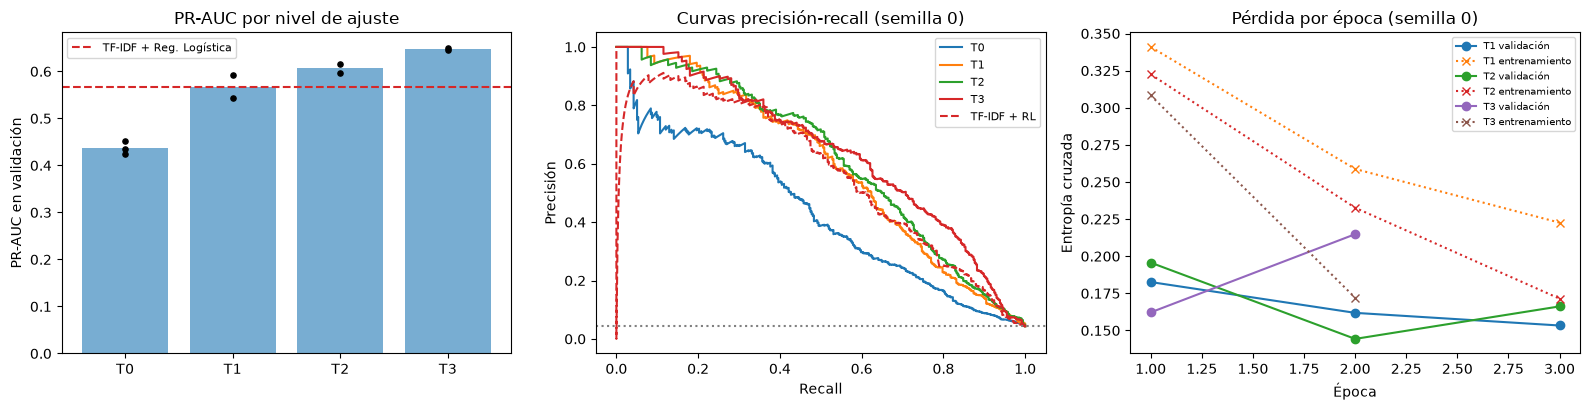

In [10]:
res = pd.DataFrame(resultados_t)
res.to_csv(SALIDAS / "resultados_transferencia.csv", index=False)
cols = ["PR-AUC", "F1 racista @opt", "precisión @opt", "recall @opt", "F1 macro @opt", "pérdida val", "parámetros entrenables", "s/paso (mediana)"]
media = res.groupby("nivel")[cols].mean(); sd = res.groupby("nivel")[cols].std(ddof=1)
resumen = media.round(3).astype(str)
for c in cols[:6]:
    resumen[c] = [f"{m:.3f} ± {0 if np.isnan(s) else s:.3f}" for m, s in zip(media[c], sd[c])]
resumen["parámetros entrenables"] = media["parámetros entrenables"].map(lambda v: f"{v / 1e6:.1f} M" if v > 1e5 else f"{int(v):,}")
resumen["s/paso (mediana)"] = media["s/paso (mediana)"].round(3).astype(str)
resumen["n semillas"] = res.groupby("nivel").size()
print(resumen.to_string())
print(f"\nContexto — TF-IDF + Reg. Logística: PR-AUC = {m_lr['PR-AUC']:.3f}, F1 racista @opt = {m_lr['F1 racista @opt']:.3f}, "
      f"precisión @opt = {m_lr['precisión @opt']:.3f}, recall @opt = {m_lr['recall @opt']:.3f}")
print("Contexto — 7.2 (ajuste completo, una sola tasa 4e-5, 1 semilla): PR-AUC = 0.484, F1 racista @opt = 0.593")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
orden = ["T0", "T1", "T2", "T3"]
for i, nv in enumerate(orden):
    pts = res[res.nivel == nv]["PR-AUC"]
    axes[0].bar(i, pts.mean(), color="tab:blue", alpha=0.6); axes[0].scatter(np.full(len(pts), i), pts, color="black", zorder=3, s=14)
axes[0].axhline(m_lr["PR-AUC"], color="tab:red", linestyle="--", label="TF-IDF + Reg. Logística")
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(orden); axes[0].set_ylabel("PR-AUC en validación"); axes[0].set_title("PR-AUC por nivel de ajuste"); axes[0].legend(fontsize=8)
for nv in orden:
    h, prob = curvas_t[(nv, 0)]; p, r, _ = precision_recall_curve(y_va, prob); axes[1].plot(r, p, label=nv)
p, r, _ = precision_recall_curve(y_va, prob_lr); axes[1].plot(r, p, "--", color="tab:red", label="TF-IDF + RL")
axes[1].axhline(y_va.mean(), color="gray", linestyle=":"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precisión"); axes[1].set_title("Curvas precisión-recall (semilla 0)"); axes[1].legend(fontsize=8)
for nv in ["T1", "T2", "T3"]:
    h, _ = curvas_t[(nv, 0)]; axes[2].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker="o", label=f"{nv} validación")
    axes[2].plot(range(1, len(h["loss"]) + 1), h["loss"], marker="x", linestyle=":", label=f"{nv} entrenamiento")
axes[2].set_xlabel("Época"); axes[2].set_ylabel("Entropía cruzada"); axes[2].set_title("Pérdida por época (semilla 0)"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(SALIDAS / "fig_transferencia.png", dpi=150)
print("Figura guardada en:", SALIDAS / "fig_transferencia.png")

**Lectura.**

- **Más capas entrenables, mejor ordenamiento.** El PR-AUC crece de forma monótona con las capas descongeladas: T0 0.437 ± 0.013, T1 0.568 ± 0.035, T2 0.606 ± 0.013 y T3 0.648 ± 0.004. La diferencia entre T3 y T2 (0.041) es más de tres veces la dispersión observada (0.013); entre T1 y T2 (0.038) es similar a la dispersión de T1 (0.035), así que ahí la evidencia es más débil. El F1 de la clase racista con umbral óptimo sigue el mismo orden (0.466, 0.560, 0.585 y 0.618).
- **El extractor congelado no basta.** T0, con 1,538 parámetros entrenables, queda muy por debajo de la línea base clásica (PR-AUC de 0.437 frente a 0.567): los vectores generales de BETO no separan la clase racista en este dominio sin adaptar el codificador, en línea con la distancia léxica de la sección 2.
- **El costo crece con el ajuste.** Cada paso cuesta 0.23 s en T1, 0.36 s en T2 y 0.88 s en T3, y los parámetros entrenables pasan de 14.8 M a 109.9 M (T0 no es comparable: sus vectores se calculan una sola vez, aparte). T3 cuesta unas 4 veces más por paso que T1 y mejora el PR-AUC en 0.08.
- **La pérdida de validación no coincide con el PR-AUC.** La pérdida es algo menor en T2 (0.126) que en T3 (0.133, con dispersión de ± 0.041). La pérdida mide la calibración de las probabilidades, alterada por el submuestreo 5:1 del entrenamiento; el PR-AUC mide la calidad del ordenamiento, que es lo que importa al elegir un umbral. La regla fijada de antemano usa el PR-AUC.
- **Frente a la línea base clásica.** T3 (PR-AUC de 0.648) y T2 (0.606) superan a TF-IDF + Regresión Logística (0.567), T1 (0.568) la iguala y T0 queda por debajo. Con el umbral óptimo de cada modelo, T3 logra F1 de la clase racista de 0.618 (precisión de 0.626 y recall de 0.610) frente a 0.567 (0.577 y 0.556). Es validación, con umbrales elegidos en ella y solo 2 semillas: el dictamen se hace en la prueba (7.4).
- **Las tasas diferenciadas importan.** El ajuste completo con una sola tasa de 4e-5 (7.2, una semilla) obtuvo un PR-AUC de 0.484; con tasa de 1e-3 en la cabeza y 3e-5 en el codificador (T3) llegó a 0.648. La comparación mezcla dos cambios y una sola semilla en 7.2, de modo que es un indicio de que la tasa de la cabeza es un factor relevante, no un efecto aislado.
- **Parada.** T3 se detuvo tras 2 épocas con la mejor en la 1, igual que en 7.2: la pérdida de validación sube desde la segunda época. En cambio T1 (semilla 0) mejoró hasta la época 3, el máximo permitido, por lo que sus resultados podrían subestimar ese nivel.

In [11]:
# Aplicación de la regla de decisión fijada de antemano
pr = res.groupby("nivel")["PR-AUC"].agg(["mean", "std"]).sort_values("mean", ascending=False)
mejor = pr.index[0]; segundo = pr.index[1]
dif = pr.loc[mejor, "mean"] - pr.loc[segundo, "mean"]
sd_ref = np.nanmax([pr.loc[mejor, "std"], pr.loc[segundo, "std"]])
par = res.groupby("nivel")["parámetros entrenables"].first()
elegido = mejor
if dif < sd_ref and par[segundo] < par[mejor]:
    elegido = segundo
print(f"Mayor PR-AUC medio: {mejor} ({pr.loc[mejor, 'mean']:.3f}); segundo: {segundo} ({pr.loc[segundo, 'mean']:.3f}); diferencia = {dif:.3f}; "
      f"desviación de referencia = {sd_ref:.3f}")
print(f"CONFIGURACIÓN ELEGIDA: {elegido}")
json.dump({"nivel": elegido, "checkpoint": CHECKPOINT, **COMUN, **NIVELES[elegido], "criterio": "mayor PR-AUC medio en validación; si la diferencia es menor que una desviación, el que entrena menos parámetros"},
          open(SALIDAS / "configuracion_elegida.json", "w"), indent=1)

Mayor PR-AUC medio: T3 (0.648); segundo: T2 (0.606); diferencia = 0.041; desviación de referencia = 0.013
CONFIGURACIÓN ELEGIDA: T3


**Lectura.** La regla fijada de antemano elige **T3, ajuste completo**: su PR-AUC medio (0.648) supera al de T2 (0.606) en 0.041, más que la desviación de referencia (0.013), por lo que no se aplica el desempate por menor costo. La configuración queda guardada en `salidas_71/configuracion_elegida.json` y es la que se evaluará una sola vez en el conjunto de prueba (7.4).

## 5. Conclusiones de la estrategia de transferencia (7.3)

- **Modelo preentrenado.** BETO uncased, por la evidencia de 7.1 sobre tuits en español (supera a mBERT y a la versión *cased*) y por continuidad con el artículo.
- **Distancia de dominio.** Moderada y sobre todo léxica y de registro: la tokenización de BETO cubre bien los comentarios, pero el vocabulario difiere del de las noticias y hay rasgos informales; además, la tarea de clasificación es nueva para el modelo.
- **Hasta dónde descongelar.** Hasta el final (12 capas y embeddings). El PR-AUC en validación sube con cada nivel (0.437, 0.568, 0.606 y 0.648) y supera a la línea base clásica (0.567) desde T2; el extractor congelado queda muy por debajo.
- **Tasas de aprendizaje.** Diferenciadas: 1e-3 para la cabeza (se inicializa al azar) y 3e-5 para el codificador, con *warm-up* del 6 %, decaimiento lineal, recorte de gradiente a 1.0, lote de 16 y longitud máxima de 64.
- **Criterio de parada.** Hasta 3 épocas, con parada si la pérdida de validación no mejora respecto de la época anterior y conservando la mejor época (en T0, hasta 30 épocas y paciencia 3).
- **Decisión.** T3, por la regla fijada de antemano (mayor PR-AUC medio en validación). La elección queda guardada y la prueba no se usó.

**Límites.** Solo 2 semillas en T1-T3 (3 en T0); el máximo de 3 épocas pudo cortar a T1; los umbrales se eligieron sobre la misma validación; el submuestreo 5:1 altera las probabilidades; solo se evaluó un modelo preentrenado (queda pendiente un modelo entrenado con tuits en español, como RoBERTuito); y la cifra de palabras de los comentarios ausentes en las noticias depende del tamaño de la muestra de noticias.

---
# **Fase 2 · 7.4 Dinámica del entrenamiento y comparación contra la línea base**

Esta sección responde dos preguntas con el **conjunto de prueba congelado**: (1) ¿cómo se comporta el entrenamiento (convergencia, estabilidad, sobreajuste y gradiente)? y (2) ¿mejora la arquitectura profunda a la línea base, en qué magnitud y a qué costo? La entrega anterior comparó modelos en conjuntos distintos y mostró curvas que no correspondían a la corrida reportada; aquí se corrige con un protocolo fijado antes de ver los resultados:

1. **Un único conjunto de prueba** (8,175 tuits, 355 racistas; huella verificada), usado solo para reportar. Ninguna decisión (configuración, época, umbral) se toma con él: la configuración viene de 7.3, la época se elige por la pérdida de validación y el **umbral por validación** (el que maximiza el F1 de la clase racista).
2. **Todos los modelos se evalúan sobre exactamente las mismas observaciones**: línea base ingenua, TF-IDF + Regresión Logística, TF-IDF + Linear SVM y los cuatro niveles de BETO (T0-T3).
3. **Las curvas salen de las mismas corridas** cuyos resultados aparecen en las tablas: cada corrida guarda el historial por paso y las predicciones de prueba de su mejor época.
4. **Variabilidad:** T3 (la configuración elegida) con 3 semillas de entrenamiento con la misma partición; T1 y T2 con 2 y T0 con 3. Se reportan media y desviación entre semillas y, para la prueba, intervalos *bootstrap* de 95 %.
5. **Métrica principal:** F1 macro (definida en la Fase 1), junto con precisión, recall y F1 de la clase racista, PR-AUC y matriz de confusión.

In [1]:
import os, sys, json, time, re, hashlib, subprocess
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, precision_recall_fscore_support, confusion_matrix

SALIDAS = Path("salidas_71")
SEED = 42
REPO_ID = "piuba-bigdata/contextualized_hate_speech"
REVISION = "01aa9dcf5cdf81c14b412bf1b9c5e6b5fba9f98d"
CHECKPOINT = "dccuchile/bert-base-spanish-wwm-uncased"
config_elegida = json.load(open(SALIDAS / "configuracion_elegida.json"))
print("Configuración elegida en 7.3:", config_elegida["nivel"], "| tasa codificador:", config_elegida["lr_enc"], "| tasa cabeza:", config_elegida["lr_head"])

def normalizacion_minima(s):
    s = s.str.replace(r"https?://\S+", " url ", regex=True)
    s = s.str.replace(r"@\w+", " usuario ", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

# Corpus local con la partición congelada de 7.2
partes = [pd.read_parquet(hf_hub_download(REPO_ID, f"data/{n}-00000-of-00001.parquet", repo_type="dataset", revision=REVISION),
                          columns=["id", "text", "RACISM"]) for n in ["train", "dev", "test"]]
todos = pd.concat(partes).drop_duplicates("id")
part = pd.read_csv(SALIDAS / "particion_local.csv").merge(todos, on="id")
tr, va, te = (part[part.particion == p] for p in ("train", "val", "test"))
y_tr, y_va, y_te = tr["RACISM"].to_numpy(), va["RACISM"].to_numpy(), te["RACISM"].to_numpy()

huella = hashlib.sha256("".join(map(str, sorted(te["id"]))).encode()).hexdigest()[:16]
assert huella == "a6919b60a4886b72", "el conjunto de prueba cambió"
print(f"Prueba congelada verificada (huella {huella}): {len(te):,} tuits, {int(y_te.sum())} racistas ({100 * y_te.mean():.2f} %)")

datos = json.load(open(SALIDAS / "datos_local.json", encoding="utf-8"))
assert (np.array(datos["eval_y"]) == y_va).all(), "la validación no coincide con 7.2/7.3"
json.dump({"test_text": normalizacion_minima(te["text"].reset_index(drop=True)).tolist()},
          open(SALIDAS / "datos_test.json", "w", encoding="utf-8"))   # solo los textos; las etiquetas no salen de este cuaderno

Configuración elegida en 7.3: T3 | tasa codificador: 3e-05 | tasa cabeza: 0.001
Prueba congelada verificada (huella a6919b60a4886b72): 8,175 tuits, 355 racistas (4.34 %)


## 1. Líneas base clásicas y protocolo de umbral

Los modelos clásicos se entrenan con las **38,065 filas** de entrenamiento (prevalencia real) y la normalización mínima de 7.2. La constante de regularización se elige **sobre validación** (F1 macro). Todos los modelos usan el mismo protocolo de decisión: el umbral se elige en validación (el que maximiza el F1 de la clase racista) y se aplica sin cambios a la prueba. El predictor ingenuo siempre responde «no racista».

In [2]:
def mejor_umbral(y, puntaje):
    p, r, t = precision_recall_curve(y, puntaje)
    f = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    return float(t[np.argmax(f)])

def metricas_umbral(y, puntaje, umbral):
    pred = (puntaje >= umbral).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"F1 macro": f1_score(y, pred, average="macro"), "precisión (racista)": p[0], "recall (racista)": r[0],
            "F1 (racista)": f[0], "PR-AUC": average_precision_score(y, puntaje), "TN": tn, "FP": fp, "FN": fn, "TP": tp}

txt_tr, txt_va, txt_te = (normalizacion_minima(d["text"]) for d in (tr, va, te))
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
A, B, Cte = vec.fit_transform(txt_tr), vec.transform(txt_va), vec.transform(txt_te)

modelos_clasicos = {}
for nombre, grilla, fabrica in [
    ("TF-IDF + Reg. Logística", [0.01, 0.1, 1, 10, 100], lambda C: LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED)),
    ("TF-IDF + Linear SVM", [0.01, 0.1, 1, 10], lambda C: LinearSVC(C=C, class_weight="balanced", max_iter=20000, random_state=SEED)),
]:
    mejor = None
    for C in grilla:
        m = fabrica(C).fit(A, y_tr)
        f1v = f1_score(y_va, m.predict(B), average="macro")
        if mejor is None or f1v > mejor[0]:
            mejor = (f1v, C, m)
    _, C_sel, m = mejor
    puntaje = (lambda X: m.predict_proba(X)[:, 1]) if hasattr(m, "predict_proba") else m.decision_function
    t0 = time.perf_counter(); s_te = puntaje(vec.transform(txt_te)); seg_inf = time.perf_counter() - t0
    modelos_clasicos[nombre] = dict(C=C_sel, val=puntaje(B), test=s_te, umbral=mejor_umbral(y_va, puntaje(B)),
                                    inferencia_1000=1000 * seg_inf / len(y_te))
    print(f"{nombre}: C = {C_sel} | umbral elegido en validación = {modelos_clasicos[nombre]['umbral']:.3f}")

TF-IDF + Reg. Logística: C = 100 | umbral elegido en validación = 0.689


TF-IDF + Linear SVM: C = 1 | umbral elegido en validación = 0.245


## 2. Corridas finales de BETO (T0-T3) con registro de la dinámica

Cada corrida entrena en un proceso aparte (como en 7.1-7.3) con exactamente la configuración de 7.3: tasas diferenciadas (cabeza 1e-3, codificador 3e-5 en T1-T3), *warm-up* del 6 %, decaimiento lineal, recorte de gradiente a 1.0, lote 16, longitud 64, hasta 3 épocas y parada si la pérdida de validación no mejora (la mejor época se elige solo con validación). Además de lo de 7.3, cada corrida guarda:

- por **paso**: la pérdida, la **norma global del gradiente antes del recorte** y la norma por grupo (codificador y cabeza);
- la pérdida de **validación cada media época** (solo para el diagnóstico; la selección sigue siendo por época completa);
- los **logits de prueba de la mejor época** (calculados por inferencia; no intervienen en ninguna decisión) y el tiempo de inferencia.

In [3]:
%%writefile bert_worker_final.py
# Corrida final (T0-T3): guarda historial por paso, gradientes, logits de validación y de prueba de la mejor época.
import os, sys, json, time, random
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
import tf_keras
from transformers import AutoTokenizer, TFAutoModel, TFAutoModelForSequenceClassification


def lotes(tok, txt, tam, max_len, orden=None):
    idx = np.arange(len(txt)) if orden is None else orden
    for i in range(0, len(idx), tam):
        b = idx[i:i + tam]
        enc = tok([txt[j] for j in b], padding=True, pad_to_multiple_of=16, truncation=True, max_length=max_len, return_tensors="tf")
        yield b, dict(enc)


def correr_t0(a, datos, test, tok, perdida):
    """Extractor congelado: promedio de la última capa de BETO (modo inferencia) + cabeza lineal."""
    rutas = {k: f"{a['features']}_{k}.npy" for k in ("train", "val", "test")}
    textos = {"train": datos["train_text"], "val": datos["eval_text"], "test": test["test_text"]}
    if not all(os.path.exists(r) for r in rutas.values()):
        bert = TFAutoModel.from_pretrained(a["checkpoint"])
        for k, txt in textos.items():
            if os.path.exists(rutas[k]):
                continue
            fs = []
            for _, enc in lotes(tok, txt, 64, a["max_len"]):
                h = bert(enc, training=False).last_hidden_state.numpy(); m = enc["attention_mask"].numpy()[..., None]
                fs.append((h * m).sum(1) / m.sum(1))
            np.save(rutas[k], np.concatenate(fs))
    Xtr, Xva, Xte = (np.load(rutas[k]) for k in ("train", "val", "test"))
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    Xtr, Xva, Xte = (Xtr - mu) / sd, (Xva - mu) / sd, (Xte - mu) / sd
    y, ev_y = np.array(datos["train_y"]), np.array(datos["eval_y"])
    tf.random.set_seed(a["semilla"]); np.random.seed(a["semilla"])
    pasos = {"loss": [], "g_tot": [], "g_enc": [], "g_cab": []}
    with tf.device("/CPU:0"):
        cabeza = tf_keras.Sequential([tf_keras.layers.Dense(2, input_shape=(Xtr.shape[1],))])
        opt = tf_keras.optimizers.legacy.Adam(learning_rate=a["lr_head"])
        hist = {"loss": [], "val_loss": []}; curva = []; mejor, espera, mejor_ep = 1e9, 0, 0; lg_va = lg_te = None
        rng = np.random.RandomState(a["semilla"]); tiempos = []; paso = 0
        for ep in range(a["epocas"]):
            orden = rng.permutation(len(y)); perd = []
            for i in range(0, len(y), 64):
                b = orden[i:i + 64]; t0 = time.perf_counter()
                with tf.GradientTape() as cinta:
                    l = perdida(y[b], cabeza(Xtr[b]))
                gr = cinta.gradient(l, cabeza.trainable_variables)
                pasos["g_tot"].append(float(tf.linalg.global_norm(gr)))
                opt.apply_gradients(zip(gr, cabeza.trainable_variables)); paso += 1
                perd.append(float(l) * len(b)); pasos["loss"].append(float(l)); tiempos.append(time.perf_counter() - t0)
            lg = cabeza(Xva).numpy(); vl = float(perdida(ev_y, lg))
            hist["loss"].append(sum(perd) / len(y)); hist["val_loss"].append(vl); curva.append((paso, vl))
            if vl < mejor - 1e-6:
                mejor, espera, mejor_ep, lg_va, lg_te = vl, 0, ep + 1, lg, cabeza(Xte).numpy()
            else:
                espera += 1
                if espera >= a["paciencia"]:
                    break
    pasos["g_enc"] = [0.0] * len(pasos["loss"]); pasos["g_cab"] = pasos["g_tot"]
    return hist, curva, lg_va, lg_te, mejor_ep, int(sum(np.prod(v.shape) for v in cabeza.trainable_variables)), float(np.median(tiempos)), None, pasos


def correr_ft(a, datos, test, tok, perdida):
    textos, y = datos["train_text"], np.array(datos["train_y"])
    ev_txt, ev_y = datos["eval_text"], np.array(datos["eval_y"])
    modelo = TFAutoModelForSequenceClassification.from_pretrained(a["checkpoint"], num_labels=2)
    capas = modelo.bert.encoder.layer; n_capas = len(capas); k = a["n_desc"]
    modelo.bert.embeddings.trainable = (k == n_capas)
    for i, c in enumerate(capas):
        c.trainable = i >= n_capas - k
    vars_cab = [v for v in modelo.trainable_variables if "pooler" in v.name or "classifier" in v.name]
    vars_enc = [v for v in modelo.trainable_variables if not ("pooler" in v.name or "classifier" in v.name)]
    n_param = int(sum(np.prod(v.shape) for v in modelo.trainable_variables))

    n, lote, epocas = len(textos), a["lote"], a["epocas"]
    pasos_ep = int(np.ceil(n / lote)); total = pasos_ep * epocas; pasos_warm = int(a["warmup"] * total)
    lr_enc, lr_cab = tf.Variable(a["lr_enc"], trainable=False), tf.Variable(a["lr_head"], trainable=False)
    opt_enc = tf_keras.optimizers.legacy.Adam(learning_rate=lr_enc, epsilon=1e-8)
    opt_cab = tf_keras.optimizers.legacy.Adam(learning_rate=lr_cab, epsilon=1e-8)

    def factor(paso):
        return paso / max(1, pasos_warm) if paso < pasos_warm else max(0.0, (total - paso) / max(1, total - pasos_warm))

    @tf.function(reduce_retracing=True)
    def paso_entrenamiento(entrada, etiquetas):
        with tf.GradientTape() as cinta:
            l = perdida(etiquetas, modelo(entrada, training=True).logits)
        todas = vars_enc + vars_cab
        grads = cinta.gradient(l, todas)
        g_enc = tf.linalg.global_norm(grads[:len(vars_enc)]) if vars_enc else tf.constant(0.0)
        g_cab = tf.linalg.global_norm(grads[len(vars_enc):])
        g_tot = tf.linalg.global_norm(grads)
        grads, _ = tf.clip_by_global_norm(grads, a["recorte"])
        if vars_enc:
            opt_enc.apply_gradients(zip(grads[:len(vars_enc)], vars_enc))
        opt_cab.apply_gradients(zip(grads[len(vars_enc):], vars_cab))
        return l, g_tot, g_enc, g_cab

    t_inf = []
    def predecir(txt):
        out = []
        for _, enc in lotes(tok, txt, 64, a["max_len"]):
            t0 = time.perf_counter(); out.append(modelo(enc, training=False).logits.numpy()); t_inf.append((time.perf_counter() - t0, len(enc["input_ids"])))
        return np.concatenate(out)

    pasos = {"loss": [], "g_tot": [], "g_enc": [], "g_cab": []}
    hist = {"loss": [], "val_loss": []}; curva = []; rng = np.random.RandomState(a["semilla"]); paso = 0
    mejor, espera, mejor_ep, lg_va, lg_te, tiempos = 1e9, 0, 0, None, None, []
    mitad = pasos_ep // 2
    for ep in range(epocas):
        orden = rng.permutation(n); perd = []; i_ep = 0
        for b, enc in lotes(tok, textos, lote, a["max_len"], orden):
            f = factor(paso); lr_enc.assign(a["lr_enc"] * f); lr_cab.assign(a["lr_head"] * f); paso += 1; i_ep += 1
            t0 = time.perf_counter()
            l, gt, ge, gc = paso_entrenamiento(enc, tf.constant(y[b]))
            perd.append(float(l) * len(b)); tiempos.append(time.perf_counter() - t0)
            pasos["loss"].append(float(l)); pasos["g_tot"].append(float(gt)); pasos["g_enc"].append(float(ge)); pasos["g_cab"].append(float(gc))
            if i_ep == mitad:                       # diagnóstico a media época (no interviene en la selección)
                curva.append((paso, float(perdida(ev_y, predecir(ev_txt)))))
        lg = predecir(ev_txt); vl = float(perdida(ev_y, lg))
        hist["loss"].append(sum(perd) / n); hist["val_loss"].append(vl); curva.append((paso, vl))
        with open(a["log"], "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {a['etiqueta']} época {ep + 1}/{epocas} pérdida {hist['loss'][-1]:.4f} pérdida val {vl:.4f}\n")
        if vl < mejor - 1e-6:
            mejor, espera, mejor_ep, lg_va = vl, 0, ep + 1, lg
            lg_te = predecir(test["test_text"])      # solo inferencia; se guarda la de la mejor época por validación
        else:
            espera += 1
            if espera >= a["paciencia"]:
                break
    med = float(np.median([t / m for t, m in t_inf if m == 64]))      # s por tuit en lotes completos
    return hist, curva, lg_va, lg_te, mejor_ep, n_param, float(np.median(tiempos)), med * 1000, pasos


if __name__ == "__main__":
    a = json.loads(sys.argv[1])
    os.environ["PYTHONHASHSEED"] = str(a["semilla"])
    random.seed(a["semilla"]); np.random.seed(a["semilla"]); tf.random.set_seed(a["semilla"])
    datos = json.load(open(a["datos"], encoding="utf-8")); test = json.load(open(a["datos_test"], encoding="utf-8"))
    tok = AutoTokenizer.from_pretrained(a["checkpoint"])
    perdida = tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    f = correr_t0 if a["config"] == "T0" else correr_ft
    hist, curva, lg_va, lg_te, mejor_ep, n_param, paso_med, inf_1000, pasos = f(a, datos, test, tok, perdida)
    np.save(a["salida"] + "_val_logits.npy", lg_va); np.save(a["salida"] + "_test_logits.npy", lg_te)
    np.savez(a["salida"] + "_pasos.npz", **{k: np.array(v) for k, v in pasos.items()})
    json.dump({"hist": hist, "curva_val": curva, "mejor_epoca": mejor_ep, "parametros_entrenables": n_param, "paso_mediano_s": paso_med,
               "inferencia_s_por_1000": inf_1000, "epocas_ejecutadas": len(hist["loss"]), "pasos_totales": len(pasos["loss"])}, open(a["salida"] + ".json", "w"))

Overwriting bert_worker_final.py


In [4]:
RUNS = SALIDAS / "corridas_finales"; RUNS.mkdir(exist_ok=True)
COMUN = {k: config_elegida[k] for k in ("checkpoint", "lote", "max_len", "warmup", "recorte", "lr_head")}
COMUN.update(datos=str(SALIDAS / "datos_local.json"), datos_test=str(SALIDAS / "datos_test.json"),
             log=str(SALIDAS / "progreso_bert.log"), features=str(SALIDAS / "features_T0"))
NIVELES = {"T0": dict(n_desc=0, lr_enc=0.0, epocas=30, paciencia=3), "T1": dict(n_desc=2, lr_enc=3e-5, epocas=3, paciencia=1),
           "T2": dict(n_desc=4, lr_enc=3e-5, epocas=3, paciencia=1), "T3": dict(n_desc=12, lr_enc=3e-5, epocas=3, paciencia=1)}
assert NIVELES[config_elegida["nivel"]]["n_desc"] == config_elegida["n_desc"], "la configuración no coincide con la elegida en 7.3"
finales = {}

def sigmoide_logit(lg):
    return np.exp(lg[:, 1] - np.logaddexp(lg[:, 0], lg[:, 1]))

def correr_final(nivel, semilla):
    etiqueta = f"{nivel}_s{semilla}"; salida = RUNS / etiqueta
    if not salida.with_suffix(".json").exists():
        args = dict(COMUN, config=nivel, semilla=semilla, etiqueta=etiqueta, salida=str(salida), **NIVELES[nivel])
        r = subprocess.run([sys.executable, "bert_worker_final.py", json.dumps(args)], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(r.stderr[-2000:])
    res = json.load(open(salida.with_suffix(".json")))
    finales[(nivel, semilla)] = dict(res=res, val=sigmoide_logit(np.load(f"{salida}_val_logits.npy")),
                                     test=sigmoide_logit(np.load(f"{salida}_test_logits.npy")), pasos=dict(np.load(f"{salida}_pasos.npz")))
    print(f"{nivel} semilla {semilla}: épocas {res['epocas_ejecutadas']} | mejor época {res['mejor_epoca']} | "
          f"pérdida val {min(res['hist']['val_loss']):.3f} | PR-AUC validación = {average_precision_score(y_va, finales[(nivel, semilla)]['val']):.3f}")

In [5]:
for s in (0, 1, 2):
    correr_final("T0", s)

T0 semilla 0: épocas 25 | mejor época 22 | pérdida val 0.186 | PR-AUC validación = 0.436


T0 semilla 1: épocas 24 | mejor época 21 | pérdida val 0.182 | PR-AUC validación = 0.425


T0 semilla 2: épocas 18 | mejor época 15 | pérdida val 0.186 | PR-AUC validación = 0.452


In [6]:
for s in (0, 1):
    correr_final("T1", s)

T1 semilla 0: épocas 3 | mejor época 3 | pérdida val 0.153 | PR-AUC validación = 0.593


T1 semilla 1: épocas 2 | mejor época 1 | pérdida val 0.119 | PR-AUC validación = 0.543


In [7]:
for s in (0, 1):
    correr_final("T2", s)

T2 semilla 0: épocas 3 | mejor época 2 | pérdida val 0.144 | PR-AUC validación = 0.616


T2 semilla 1: épocas 2 | mejor época 1 | pérdida val 0.108 | PR-AUC validación = 0.597


In [8]:
for s in (0, 1, 2):
    correr_final("T3", s)

T3 semilla 0: épocas 2 | mejor época 1 | pérdida val 0.162 | PR-AUC validación = 0.644


T3 semilla 1: épocas 2 | mejor época 1 | pérdida val 0.106 | PR-AUC validación = 0.653


T3 semilla 2: épocas 2 | mejor época 1 | pérdida val 0.097 | PR-AUC validación = 0.640


## 3. Dinámica del entrenamiento

Se diagnostican las corridas de T3 (la configuración elegida), con las tres semillas superpuestas. Las curvas salen directamente del historial de cada corrida, por paso (pérdida y norma del gradiente) y de validación cada media época, de modo que cada figura corresponde exactamente a las corridas cuyos resultados están en la sección 4.

semilla                            0       1       2
épocas                         2.000   2.000   2.000
mejor época                    1.000   1.000   1.000
pérdida inicial (50 pasos)     0.457   0.446   0.468
pérdida final (50 pasos)       0.162   0.157   0.138
pérdida entren. última época   0.172   0.174   0.179
pérdida val. mínima            0.162   0.106   0.097
pérdida val. última            0.206   0.186   0.167
norma gradiente mediana        5.738   6.448   6.117
norma gradiente máx.          48.483  96.517  57.929
% pasos recortados            87.803  89.661  88.288
Figura guardada en: salidas_71/fig_dinamica_t3.png


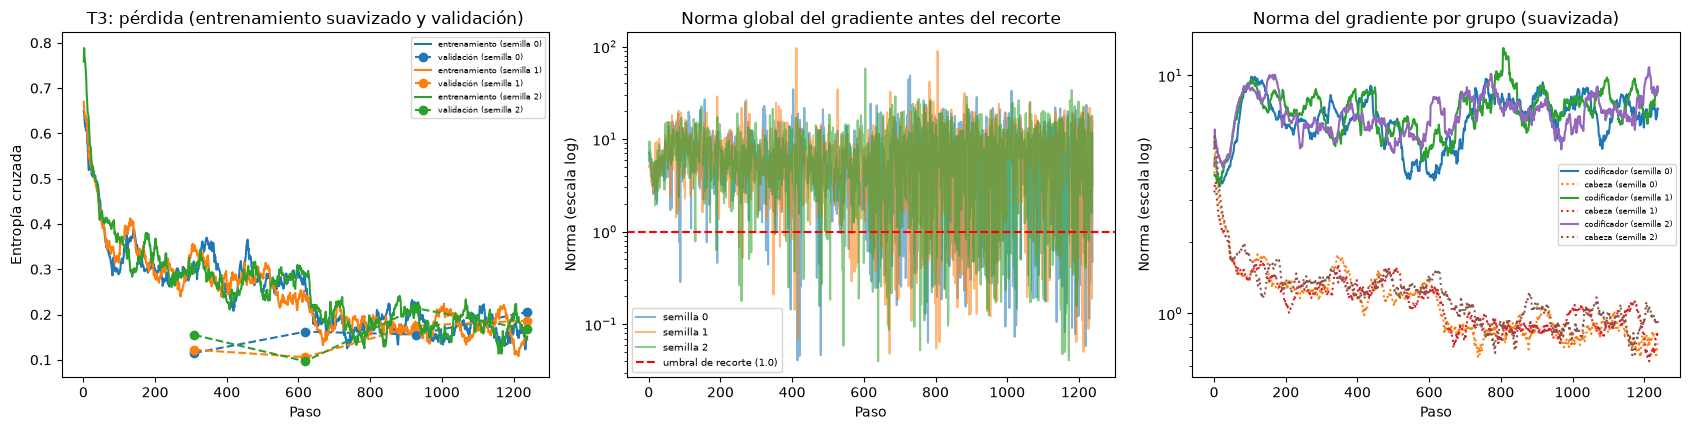

In [9]:
def suavizar(x, v=40):
    return pd.Series(x).rolling(v, min_periods=1).mean().to_numpy()

semillas_t3 = [s for (nv, s) in finales if nv == "T3"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for s in semillas_t3:
    f = finales[("T3", s)]; p = f["pasos"]; pasos_x = np.arange(1, len(p["loss"]) + 1)
    l, = axes[0].plot(pasos_x, suavizar(p["loss"]), label=f"entrenamiento (semilla {s})")
    cx, cy = zip(*f["res"]["curva_val"]); axes[0].plot(cx, cy, marker="o", linestyle="--", color=l.get_color(), label=f"validación (semilla {s})")
    axes[1].plot(pasos_x, p["g_tot"], alpha=0.55, label=f"semilla {s}")
    axes[2].plot(pasos_x, suavizar(p["g_enc"]), label=f"codificador (semilla {s})")
    axes[2].plot(pasos_x, suavizar(p["g_cab"]), linestyle=":", label=f"cabeza (semilla {s})")
axes[0].set_title("T3: pérdida (entrenamiento suavizado y validación)"); axes[0].set_xlabel("Paso"); axes[0].set_ylabel("Entropía cruzada"); axes[0].legend(fontsize=6)
axes[1].axhline(1.0, color="red", linestyle="--", label="umbral de recorte (1.0)"); axes[1].set_yscale("log")
axes[1].set_title("Norma global del gradiente antes del recorte"); axes[1].set_xlabel("Paso"); axes[1].set_ylabel("Norma (escala log)"); axes[1].legend(fontsize=7)
axes[2].set_yscale("log"); axes[2].set_title("Norma del gradiente por grupo (suavizada)"); axes[2].set_xlabel("Paso"); axes[2].set_ylabel("Norma (escala log)"); axes[2].legend(fontsize=6)
plt.tight_layout(); plt.savefig(SALIDAS / "fig_dinamica_t3.png", dpi=150)

filas = []
for (nv, s), f in sorted(finales.items()):
    if nv != "T3":
        continue
    p, h = f["pasos"], f["res"]["hist"]
    primeros = np.mean(p["loss"][:50]); ultimos = np.mean(p["loss"][-50:])
    filas.append({"semilla": s, "épocas": f["res"]["epocas_ejecutadas"], "mejor época": f["res"]["mejor_epoca"],
                  "pérdida inicial (50 pasos)": primeros, "pérdida final (50 pasos)": ultimos,
                  "pérdida entren. última época": h["loss"][-1], "pérdida val. mínima": min(h["val_loss"]), "pérdida val. última": h["val_loss"][-1],
                  "norma gradiente mediana": np.median(p["g_tot"]), "norma gradiente máx.": np.max(p["g_tot"]),
                  "% pasos recortados": 100 * np.mean(p["g_tot"] > 1.0)})
print(pd.DataFrame(filas).set_index("semilla").round(3).T.to_string())
print("Figura guardada en:", SALIDAS / "fig_dinamica_t3.png")

In [ ]:
# Rango de la norma suavizada del gradiente del codificador en T3 (se cita en el informe)
import numpy as np, pandas as pd
rangos = []
for s in (0, 1, 2):
    z = np.load(SALIDAS / "corridas_finales" / f"T3_s{s}_pasos.npz")
    g = pd.Series(z["g_enc"]).rolling(40, min_periods=1).mean()
    rangos.append((g.min(), g.max()))
print(f"Norma suavizada del gradiente del codificador (T3): mínimo = {min(r[0] for r in rangos):.1f}, máximo = {max(r[1] for r in rangos):.1f}")
print(f"Diferencia entre BETO y mBERT en el artículo (Tabla 5): {85.14 - 82.00:.2f} puntos")

Norma suavizada del gradiente del codificador (T3): mínimo = 3.4, máximo = 13.0
Diferencia entre BETO y mBERT en el artículo (Tabla 5): 3.14 puntos


**Lectura de la dinámica de T3** (tres semillas superpuestas; las curvas salen del historial de las mismas corridas de la sección 4).

- **Convergencia y estabilidad.** La pérdida de entrenamiento baja de ≈ 0.45 en los primeros 50 pasos a ≈ 0.15 en los últimos 50 en las tres semillas, con una caída rápida en los primeros 200 pasos, una meseta cerca de 0.3 durante el resto de la primera época y un nuevo descenso al empezar la segunda (paso ≈ 620). Las tres trayectorias son casi idénticas: el entrenamiento es estable entre semillas.
- **Sobreajuste.** La pérdida de validación es mínima hacia el final de la primera época (0.097-0.162; en la semilla 0 ya era menor a media época, 0.115) y sube en la segunda (0.167-0.206), mientras la de entrenamiento sigue bajando. Es la señal de sobreajuste desde la segunda época y por eso la parada conserva la época 1 en las tres semillas. Los niveles de ambas pérdidas no son comparables entre sí (el entrenamiento tiene 16.7 % de positivos y la validación 4.3 %, y la pérdida de entrenamiento promedia toda la época con *dropout*), de modo que se interpretan las tendencias y no la brecha.
- **Gradiente.** La norma global antes del recorte tiene mediana de 5.7 a 6.4 y máximos de 48 a 97. **Entre el 88 % y el 90 % de los pasos de T3 se recortan** (96-97 % en T1 y 92-95 % en T2): el recorte de 1.0, heredado de SimpleTransformers, casi siempre está activo, así que el tamaño real del paso lo fija el recorte y no la magnitud natural del gradiente. No hay divergencia ni gradiente que se desvanezca (la norma del codificador se mantiene entre ≈ 4 y 10 durante todo el entrenamiento y los picos aislados no se ven en la pérdida), pero ese valor de recorte es más agresivo de lo necesario y no se ajustó. La norma de la cabeza cae de ≈ 4 a ≈ 1 a medida que aprende y la del codificador domina la norma total.

In [10]:
# Brecha entre entrenamiento y validación por época, y estabilidad entre semillas, para los cuatro niveles
filas = []
for (nv, s), f in sorted(finales.items()):
    h = f["res"]["hist"]
    filas.append({"nivel": nv, "semilla": s, "épocas": f["res"]["epocas_ejecutadas"], "mejor época": f["res"]["mejor_epoca"],
                  "pérdida entren. (mejor época)": h["loss"][f["res"]["mejor_epoca"] - 1], "pérdida val. (mejor época)": min(h["val_loss"]),
                  "pérdida val. (última época)": h["val_loss"][-1], "% pasos recortados": 100 * np.mean(f["pasos"]["g_tot"] > 1.0) if f["pasos"]["g_enc"].any() or nv != "T0" else np.nan})
dinamica = pd.DataFrame(filas)
print(dinamica.round(3).to_string(index=False))
dinamica.to_csv(SALIDAS / "dinamica_entrenamiento.csv", index=False)

nivel  semilla  épocas  mejor época  pérdida entren. (mejor época)  pérdida val. (mejor época)  pérdida val. (última época)  % pasos recortados
   T0        0      25           22                          0.245                       0.186                        0.188                 NaN
   T0        1      24           21                          0.244                       0.182                        0.189                 NaN
   T0        2      18           15                          0.254                       0.186                        0.190                 NaN
   T1        0       3            3                          0.223                       0.153                        0.153              95.907
   T1        1       2            1                          0.334                       0.119                        0.156              96.688
   T2        0       3            2                          0.233                       0.144                        0.166             

**Lectura entre niveles.** El extractor congelado (T0) converge lento y se estanca (mejor época entre la 15 y la 22 de hasta 25, pérdida de validación de 0.182 a 0.186), lo que anticipa su rendimiento inferior. A mayor ajuste, antes se alcanza el mejor punto: T3 lo logra en la época 1 en las tres semillas, T2 en la 1 o la 2 y T1 en la semilla 0 solo en la 3, **la última permitida**, de modo que T1 pudo quedar sin converger dentro del límite de 3 épocas. La pérdida de validación en la mejor época varía más entre semillas del mismo nivel (por ejemplo, 0.097 a 0.162 en T3) que entre niveles, por lo que no sirve por sí sola para comparar niveles; se usan PR-AUC y las métricas de la clase racista.

## 4. Comparación contra la línea base en el conjunto de prueba

Todas las filas se calculan sobre los mismos 8,175 tuits de prueba, con el umbral elegido en validación. Para los modelos BETO se reporta la **media ± desviación entre semillas** (variabilidad del entrenamiento con la partición fija) y, para todos, el intervalo *bootstrap* de 95 % del F1 macro y del F1 de la clase racista (variabilidad del muestreo de la prueba).

In [11]:
rng = np.random.RandomState(SEED)
N = len(y_te); B_REMUESTREOS = 1000
indices = rng.randint(0, N, size=(B_REMUESTREOS, N))

def f1s_rapido(y, pred, idx):
    yy, pp = y[idx], pred[idx]
    tp = (yy * pp).sum(); fp = ((1 - yy) * pp).sum(); fn = (yy * (1 - pp)).sum(); tn = N - tp - fp - fn
    f1_pos = 2 * tp / max(1, 2 * tp + fp + fn); f1_neg = 2 * tn / max(1, 2 * tn + fn + fp)
    return (f1_pos + f1_neg) / 2, f1_pos, tp / max(1, tp + fn), tp / max(1, tp + fp)    # F1 macro, F1 racista, recall, precisión

def evaluar_modelo(puntaje_val, puntaje_te):
    u = mejor_umbral(y_va, puntaje_val)
    return {**metricas_umbral(y_te, puntaje_te, u), "umbral": u}, (puntaje_te >= u).astype(int)

filas, preds = [], {}
# predictor ingenuo
const = np.zeros(N, dtype=int)
p0, r0, f0, _ = precision_recall_fscore_support(y_te, const, labels=[1], zero_division=0)
filas.append({"modelo": "Clase mayoritaria", "semilla": "-", **{"F1 macro": f1_score(y_te, const, average="macro"), "precisión (racista)": 0.0,
              "recall (racista)": 0.0, "F1 (racista)": 0.0, "PR-AUC": y_te.mean(), "TN": int((1 - y_te).sum()), "FP": 0, "FN": int(y_te.sum()), "TP": 0}})
preds["Clase mayoritaria"] = [const]
for nombre, d in modelos_clasicos.items():
    m, pr = evaluar_modelo(d["val"], d["test"]); filas.append({"modelo": nombre, "semilla": "-", **m}); preds[nombre] = [pr]
nombres_beto = {"T0": "BETO T0 (extractor congelado)", "T1": "BETO T1 (2 últimas capas)", "T2": "BETO T2 (4 últimas capas)", "T3": "BETO T3 (ajuste completo)"}
for (nv, s), f in sorted(finales.items()):
    m, pr = evaluar_modelo(f["val"], f["test"]); filas.append({"modelo": nombres_beto[nv], "semilla": s, **m}); preds.setdefault(nombres_beto[nv], []).append(pr)
por_semilla = pd.DataFrame(filas)
por_semilla.to_csv(SALIDAS / "resultados_prueba_por_semilla.csv", index=False)

cols = ["F1 macro", "precisión (racista)", "recall (racista)", "F1 (racista)", "PR-AUC"]
resumen = []
for nombre, grupo in por_semilla.groupby("modelo", sort=False):
    fila = {"modelo": nombre, "n": len(grupo)}
    for c in cols:
        fila[c] = f"{grupo[c].mean():.3f}" + (f" ± {grupo[c].std(ddof=1):.3f}" if len(grupo) > 1 else "")
    boot = np.array([[np.mean([f1s_rapido(y_te, pr, idx)[k] for pr in preds[nombre]]) for k in (0, 1)] for idx in indices])
    fila["IC95 % F1 macro"] = f"[{np.percentile(boot[:, 0], 2.5):.3f}, {np.percentile(boot[:, 0], 97.5):.3f}]"
    fila["IC95 % F1 racista"] = f"[{np.percentile(boot[:, 1], 2.5):.3f}, {np.percentile(boot[:, 1], 97.5):.3f}]"
    resumen.append(fila)
resumen = pd.DataFrame(resumen).set_index("modelo")
resumen.to_csv(SALIDAS / "resultados_prueba_resumen.csv")
print(resumen.to_string())

                               n       F1 macro precisión (racista) recall (racista)   F1 (racista)         PR-AUC IC95 % F1 macro IC95 % F1 racista
modelo                                                                                                                                              
Clase mayoritaria              1          0.489               0.000            0.000          0.000          0.043  [0.488, 0.490]    [0.000, 0.000]
TF-IDF + Reg. Logística        1          0.766               0.599            0.510          0.551          0.559  [0.743, 0.788]    [0.506, 0.594]
TF-IDF + Linear SVM            1          0.770               0.632            0.499          0.557          0.564  [0.744, 0.793]    [0.509, 0.602]
BETO T0 (extractor congelado)  3  0.723 ± 0.003       0.464 ± 0.016    0.479 ± 0.013  0.471 ± 0.005  0.450 ± 0.007  [0.703, 0.747]    [0.431, 0.517]
BETO T1 (2 últimas capas)      2  0.770 ± 0.015       0.603 ± 0.095    0.527 ± 0.024  0.560 ± 0.028  0.571

**Lectura de la comparación (conjunto de prueba, mismas observaciones para todos los modelos).**

- **Punto de partida.** El predictor ingenuo obtiene F1 macro de 0.489. Las líneas base clásicas obtienen 0.766 (Regresión Logística) y 0.770 (SVM lineal), prácticamente iguales; se toma la SVM como referencia por su F1 macro, aunque la diferencia con la Regresión Logística no es significativa.
- **BETO mejora con las capas descongeladas, en el mismo orden que en validación (7.3):** T0 queda por debajo de las líneas base (0.723), T1 las iguala (0.770 ± 0.015), T2 queda algo por encima con intervalos que se solapan (0.781 ± 0.002) y T3 (ajuste completo) alcanza 0.803 ± 0.009 (IC 95 %: 0.784-0.823).
- **PR-AUC.** T3 llega a 0.656 ± 0.004 frente a 0.559-0.564 de las líneas base (+0.09): el ordenamiento de probabilidades de T3 es mejor en todos los umbrales y no solo en el elegido.
- **Clase racista.** T3 obtiene F1 de 0.623 ± 0.019 frente a 0.557 de la SVM. La mejora proviene del **recall** (0.615 ± 0.062 frente a 0.499), con precisión similar (0.636 ± 0.031 frente a 0.632).
- **Variabilidad.** La desviación entre semillas del F1 macro de T3 (0.009) es menor que la mitad del ancho del intervalo bootstrap de la prueba (≈ ± 0.02), así que la incertidumbre dominante es el tamaño de la prueba (355 positivos) y no el azar del entrenamiento. Pero el recall de T3 va de 0.544 a 0.659 según la semilla porque el umbral elegido en validación cambia (0.565, 0.645 y 0.951): el ordenamiento es estable y el punto de operación no, de modo que la elección del umbral es la parte frágil del protocolo.

Matrices de confusión en PRUEBA [[TN, FP], [FN, TP]] con el umbral elegido en validación:
  TF-IDF + Reg. Logística: [[7699, 121], [174, 181]]
  BETO T3 (ajuste completo): [[7680, 140], [127, 228]]
Figura guardada en: salidas_71/fig_comparacion_prueba.png


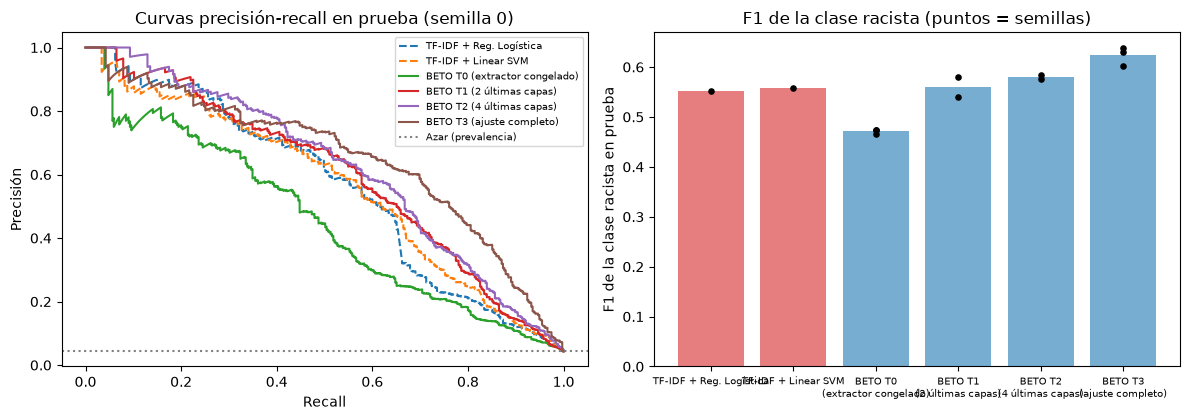

In [12]:
# Matrices de confusión de la línea base principal y de T3 (semilla 0), con el umbral elegido en validación
print("Matrices de confusión en PRUEBA [[TN, FP], [FN, TP]] con el umbral elegido en validación:")
for nombre in ["TF-IDF + Reg. Logística", "BETO T3 (ajuste completo)"]:
    g = por_semilla[por_semilla.modelo == nombre].iloc[0]
    print(f"  {nombre}: [[{g.TN}, {g.FP}], [{g.FN}, {g.TP}]]")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for nombre, d in modelos_clasicos.items():
    p, r, _ = precision_recall_curve(y_te, d["test"]); axes[0].plot(r, p, "--", label=nombre)
for nv in ["T0", "T1", "T2", "T3"]:
    f = finales[(nv, 0)]; p, r, _ = precision_recall_curve(y_te, f["test"]); axes[0].plot(r, p, label=nombres_beto[nv])
axes[0].axhline(y_te.mean(), color="gray", linestyle=":", label="Azar (prevalencia)")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precisión"); axes[0].set_title("Curvas precisión-recall en prueba (semilla 0)"); axes[0].legend(fontsize=7)

orden = ["TF-IDF + Reg. Logística", "TF-IDF + Linear SVM"] + list(nombres_beto.values())
for i, nombre in enumerate(orden):
    g = por_semilla[por_semilla.modelo == nombre]["F1 (racista)"]
    axes[1].bar(i, g.mean(), color="tab:red" if i < 2 else "tab:blue", alpha=0.6); axes[1].scatter(np.full(len(g), i), g, color="black", zorder=3, s=14)
axes[1].set_xticks(range(len(orden))); axes[1].set_xticklabels([o.replace(" (", "\n(") for o in orden], fontsize=7)
axes[1].set_ylabel("F1 de la clase racista en prueba"); axes[1].set_title("F1 de la clase racista (puntos = semillas)")
plt.tight_layout(); plt.savefig(SALIDAS / "fig_comparacion_prueba.png", dpi=150)
print("Figura guardada en:", SALIDAS / "fig_comparacion_prueba.png")

**Lectura de las matrices.** Con el umbral elegido en validación, la Regresión Logística detecta 181 de los 355 mensajes racistas (174 omitidos, 121 falsos positivos) y T3 (semilla 0) detecta 228 (127 omitidos, 140 falsos positivos): 47 racistas más a cambio de 19 falsos positivos más. En la curva precisión-recall T3 domina a las líneas base en casi todo el rango de recall.

## 5. ¿Mejora la arquitectura profunda a la línea base? Magnitud, incertidumbre y costo

Se compara T3 (la configuración elegida) con la mejor línea base clásica **sobre las mismas observaciones**, con un *bootstrap* pareado: en cada remuestreo de la prueba se calcula la métrica de la línea base y la media de las semillas de T3, y se reporta la diferencia con su intervalo de 95 %. También se cuentan los tuits en los que cada modelo acierta y el otro falla, y se resume el costo de entrenamiento e inferencia.

In [13]:
ref = max(modelos_clasicos, key=lambda n: por_semilla[por_semilla.modelo == n]["F1 macro"].iloc[0])
print("Mejor línea base clásica en prueba (F1 macro):", ref)
nombres_m = ["F1 macro", "F1 (racista)", "recall (racista)", "precisión (racista)"]
dif = np.array([[np.mean([f1s_rapido(y_te, pr, idx)[k] for pr in preds["BETO T3 (ajuste completo)"]]) - f1s_rapido(y_te, preds[ref][0], idx)[k]
                 for k in range(4)] for idx in indices])
tabla_dif = pd.DataFrame({"diferencia media (T3 − base)": dif.mean(0), "IC95 % inferior": np.percentile(dif, 2.5, axis=0),
                          "IC95 % superior": np.percentile(dif, 97.5, axis=0), "P(diferencia ≤ 0)": (dif <= 0).mean(0)}, index=nombres_m)
print(tabla_dif.round(3).to_string())

# Tuits en los que cada modelo acierta y el otro falla (semilla 0 de T3 frente a la línea base)
pb, pt = preds[ref][0], preds["BETO T3 (ajuste completo)"][0]
ok_b, ok_t = (pb == y_te), (pt == y_te)
print(f"\nDiscordancias (semilla 0): solo T3 acierta: {int((ok_t & ~ok_b).sum())} | solo la línea base acierta: {int((ok_b & ~ok_t).sum())} | "
      f"ambos aciertan: {int((ok_b & ok_t).sum())} | ambos fallan: {int((~ok_b & ~ok_t).sum())}")
pos = y_te == 1
print(f"Entre los {int(pos.sum())} tuits racistas: solo T3 detecta {int((pt[pos] == 1)[pb[pos] == 0].sum())} | solo la línea base detecta {int((pb[pos] == 1)[pt[pos] == 0].sum())} | "
      f"ninguno detecta {int(((pb[pos] == 0) & (pt[pos] == 0)).sum())}")

# Costo
costo = []
for nv in ["T0", "T1", "T2", "T3"]:
    rs = [f["res"] for (n, s), f in finales.items() if n == nv]
    costo.append({"modelo": nombres_beto[nv], "parámetros entrenables": f"{np.mean([r['parametros_entrenables'] for r in rs]):,.0f}",
                  "s por paso (mediana)": round(np.mean([r["paso_mediano_s"] for r in rs]), 3),
                  "pasos de entrenamiento": int(np.mean([r["pasos_totales"] for r in rs])),
                  "minutos de entrenamiento (≈)": round(np.mean([r["paso_mediano_s"] * r["pasos_totales"] for r in rs]) / 60, 1),
                  "s de inferencia por 1,000 tuits": round(np.mean([r["inferencia_s_por_1000"] for r in rs if r["inferencia_s_por_1000"]]), 2) if nv != "T0" else np.nan})
for nombre, d in modelos_clasicos.items():
    costo.append({"modelo": nombre, "parámetros entrenables": f"{A.shape[1]:,} (coeficientes TF-IDF)",
                  "s por paso (mediana)": np.nan, "pasos de entrenamiento": np.nan, "minutos de entrenamiento (≈)": "segundos",
                  "s de inferencia por 1,000 tuits": round(d["inferencia_1000"], 4)})
print("\n", pd.DataFrame(costo).set_index("modelo").to_string())

Mejor línea base clásica en prueba (F1 macro): TF-IDF + Linear SVM


                     diferencia media (T3 − base)  IC95 % inferior  IC95 % superior  P(diferencia ≤ 0)
F1 macro                                    0.034            0.012            0.056              0.001
F1 (racista)                                0.066            0.024            0.110              0.001
recall (racista)                            0.116            0.070            0.165              0.000
precisión (racista)                         0.005           -0.045            0.055              0.422

Discordancias (semilla 0): solo T3 acierta: 128 | solo la línea base acierta: 114 | ambos aciertan: 7780 | ambos fallan: 153
Entre los 355 tuits racistas: solo T3 detecta 71 | solo la línea base detecta 20 | ninguno detecta 107

                                      parámetros entrenables  s por paso (mediana)  pasos de entrenamiento minutos de entrenamiento (≈)  s de inferencia por 1,000 tuits
modelo                                                                                

**Primera lectura de la comparación.**

- **Magnitud.** T3 supera a la mejor línea base clásica en F1 macro por +0.034 (IC 95 % [0.012, 0.056]), en F1 de la clase racista por +0.066 [0.024, 0.110] y en recall por +0.116 [0.070, 0.165]. En precisión la diferencia es +0.005 [−0.045, 0.055], es decir, indistinguible de cero: **la mejora es de recall, sin ganancia ni pérdida detectable de precisión**. En promedio son unos 41 mensajes racistas más detectados de 355. El intervalo captura el muestreo de la prueba y el promedio de 3 semillas, pero no la incertidumbre de la elección del umbral.
- **Qué detecta cada uno.** De los 355 racistas, T3 (semilla 0) detecta 71 que la línea base no y la línea base detecta 20 que T3 no; **107 (30 %) no los detecta ninguno**. En conjunto los dos modelos aciertan de forma distinta en 242 tuits (128 solo T3 y 114 solo la línea base).
- **Costo.** T3 entrena ≈ 17 minutos en GPU (1,238 pasos de 0.84 s) frente a segundos de la línea base; tiene ≈ 110 millones de parámetros frente a 62,924 coeficientes; y la inferencia toma ≈ 9 s por 1,000 tuits frente a ≈ 0.01 s, es decir, unas **900 veces más lenta**. Los niveles intermedios cuestan menos (T1 ≈ 6 min, T2 ≈ 9 min) pero apenas igualan a la línea base.
- **Lectura.** La arquitectura profunda **sí mejora** a la línea base en este problema, con una magnitud moderada (≈ 3 puntos de F1 macro y ≈ 12 de recall) y solo con ajuste completo, a un costo de cómputo de tres órdenes de magnitud mayor. Si el criterio es no omitir mensajes racistas (el costo del error definido en la Fase 1), el aumento de recall con precisión igual justifica considerar el modelo profundo; si el cómputo es una restricción, la línea base clásica sigue siendo una alternativa razonable. El dictamen sobre si la profundidad se justifica, que incluye la auditoría de qué aprendió el modelo, corresponde a la Fase 3.
- **Qué podría explicar el resultado (hipótesis, aún sin comprobar).** (a) Los modelos clásicos dependen de palabras concretas (insultos, gentilicios) y fallan cuando el racismo es implícito o usa vocabulario nuevo, mientras que BETO usa el contexto; eso explicaría los 71 mensajes que solo T3 detecta. (b) Que T1 y T2 apenas igualen a la línea base sugiere que adaptar las capas inferiores, donde se codifican el vocabulario y el registro, es importante (la distancia léxica de 7.3). (c) Los 107 que ninguno detecta pueden ser ambiguos o estar mal etiquetados (basta un anotador para marcar `RACISM`), lo que se estudiará en el análisis de fallas de la Fase 3.
- **Salvedades.** BETO recibió más esfuerzo de ajuste (cuatro niveles y varias rondas sobre validación) que la línea base (una búsqueda de la constante de regularización), y los casi duplicados (≈ 7 % de la prueba tiene un vecino casi idéntico en el entrenamiento) pueden favorecer a ambos tipos de modelo.

## 6. Conclusiones de la dinámica y la comparación (7.4)

- **Dinámica.** El entrenamiento de T3 es estable y reproducible entre semillas, converge en la primera época y se sobreajusta desde la segunda (la parada la corta). El recorte de gradiente de 1.0 se activa en ≈ 90 % de los pasos, sin divergencia ni gradiente que se desvanezca; es un hiperparámetro heredado que no se ajustó.
- **Comparación.** Sobre el mismo conjunto de prueba, BETO con ajuste completo mejora a la mejor línea base clásica en F1 macro (+0.034), F1 de la clase racista (+0.066) y recall (+0.116), con precisión equivalente. Los niveles parciales apenas igualan a la línea base y el extractor congelado queda por debajo.
- **Costo.** ≈ 17 minutos de entrenamiento en GPU y una inferencia ≈ 900 veces más lenta que la línea base.
- **Primera lectura.** La profundidad mejora el rendimiento de forma moderada y a un costo alto; el dictamen definitivo queda para la Fase 3, junto con la auditoría y el análisis de fallas.

**Límites.** T3 con 3 semillas y T1-T2 con 2; el punto de operación es sensible al umbral elegido en validación; el máximo de 3 épocas pudo cortar a T1; el recorte de gradiente no se ajustó; la prueba se usó una sola vez, pero sus 355 positivos dejan un intervalo de ± 0.02 en el F1 macro; y los casi duplicados pueden favorecer a todos los modelos.